In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
train_data = pd.read_csv("/Users/nathanonkhueanta/Documents/GitHub/AI_finance_hackathon/Data/train_dataset.csv")
test_data = pd.read_csv("/Users/nathanonkhueanta/Documents/GitHub/AI_finance_hackathon/Data/test_without_gt.csv")
submission_data = pd.read_csv("/Users/nathanonkhueanta/Documents/GitHub/AI_finance_hackathon/Data/submission_template_for_test.csv")

##

## Modeling

In [3]:
# Normalie
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split

# Support Vector Machine
from sklearn.svm import SVC

# Tree-base model
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import ExtraTreesClassifier

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_auc_score
from sklearn.metrics import matthews_corrcoef
from sklearn.metrics import average_precision_score
from sklearn.metrics import RocCurveDisplay
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import precision_recall_curve
from sklearn.inspection import permutation_importance

In [5]:
df_train = train_data.copy()

In [6]:
df_train

,ID,12-Month Default Flag,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,...,Desired Credit Limit,Residence Type,Rent Burden,Residence Ownership Status,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available
0,211880002,0,18,1,2,699,141,140,8,6,...,300000,1,50000,1,2,1,1,1,1,1
1,211870004,0,20,2,2,419,26,640,1,1,...,200000,3,0,0,1,0,0,1,0,0
2,211930001,0,1,2,1,322,181,540,8,5,...,100000,1,0,3,0,0,0,1,1,1
3,211920001,0,17,1,1,328,328,640,1,5,...,100000,1,0,3,0,0,1,1,1,1
4,211880003,1,18,1,1,451,44,1040,16,1,...,100000,4,60000,0,0,0,0,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68541,215470332,0,17,1,2,372,372,640,99,5,...,200000,1,0,2,1,0,0,1,1,1
68542,215470333,0,18,2,1,362,18,640,99,5,...,50000,5,53000,0,1,1,0,1,1,0
68543,215480285,0,18,1,2,457,44,340,4,1,...,300000,1,0,2,2,1,0,1,1,1
68544,215470336,0,20,1,1,293,293,640,9,4,...,50000,2,0,3,0,0,1,1,0,0


In [7]:

def feature_and_target_func(df, feature, target):
    df = df.copy()

    f_x = df[feature].copy()
    f_y = df[target].copy()

    return f_x, f_y


def Prepra_datamodel_func(f_x, f_y):
    f_x = f_x.copy()
    f_y = np.asarray(f_y).ravel()

    return f_x, f_y


#""""

def Split_datamodel_func(f_x, f_y, size_test):

    x_train, x_val, y_train, y_val = train_test_split(
        f_x,
        f_y,
        test_size=size_test,
        random_state=42,
        stratify=f_y
    )

    print("Train:", x_train.shape, y_train.shape)
    print("Validation:", x_val.shape, y_val.shape)

    print("\nTrain Distribution:")
    print(pd.Series(y_train).value_counts(normalize=True))

    print("\nValidation Distribution:")
    print(pd.Series(y_val).value_counts(normalize=True))

    return x_train, x_val, y_train, y_val


#"""

# ==========================================
# MODEL TRAINING + CROSS VALIDATION
# ==========================================

def train_evaluate_model(
    classifier,
    x_train,
    y_train,
    x_test,
    y_test,
    n_splits=5,
    n_repeats=2
):

    cv = RepeatedStratifiedKFold(
        n_splits=n_splits,
        n_repeats=n_repeats,
        random_state=42
    )

    # 1. Cross Validation
    cv_scores = cross_val_score(
        classifier,
        x_train,
        y_train,
        cv=cv,
        scoring="roc_auc",
        n_jobs=1
    )

    print("CV ROC-AUC:",
          f"{cv_scores.mean():.4f}")

    print("CV STD:",
          f"{cv_scores.std():.4f}")

    # 2. Train Model
    classifier.fit(x_train, y_train)

    # 3. Find Positive Class
    pos_idx = np.where(classifier.classes_ == 1)[0][0]

    # 4. Probability Prediction
    y_prob = classifier.predict_proba(x_test)[:, pos_idx]

    # 5. Evaluation
    auc = roc_auc_score(y_test, y_prob)
    pr_auc = average_precision_score(y_test, y_prob)

    print("\nValidation ROC-AUC:", f"{auc:.4f}")
    print("Validation PR-AUC:", f"{pr_auc:.4f}")

    # 6. ROC Curve
    RocCurveDisplay.from_predictions(y_test, y_prob)

    plt.title(f"ROC Curve (AUC = {auc:.4f})")
    plt.grid(alpha=0.3)
    plt.show()

    return classifier, y_prob, cv_scores


# ==========================================
# MODEL EVALUATION
# ==========================================

def model_evaluation(
    classifier,
    x_test,
    y_test,
    threshold=0.5,
    y_prob=None
):

    if y_prob is None:
        pos_idx = np.where(classifier.classes_ == 1)[0][0]
        y_prob = classifier.predict_proba(x_test)[:, pos_idx]

    y_pred = (y_prob >= threshold).astype(int)

    # Confusion Matrix
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    names = [
        "True Neg",
        "False Pos",
        "False Neg",
        "True Pos"
    ]

    counts = cm.flatten()

    percentages = [
        f"{v:.2%}" for v in counts / counts.sum()
    ]

    labels = [
        f"{name}\n{count}\n{percent}"
        for name, count, percent in zip(
            names, counts, percentages
        )
    ]

    labels = np.asarray(labels).reshape(2, 2)

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm,
        annot=labels,
        fmt="",
        cmap="rocket_r",
        cbar=True
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix (Threshold = {threshold})")
    plt.show()

    # Classification Report
    print("\nClassification Report:")

    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))

    # Additional Metrics
    print("ROC-AUC:",
          roc_auc_score(y_test, y_prob))

    print("PR-AUC:",
          average_precision_score(y_test, y_prob))

    print("MCC:",
          matthews_corrcoef(y_test, y_pred))

    return y_pred


# ==========================================
# FEATURE IMPORTANCE
# ==========================================

def feature_importance_func(model, feature):

    if not hasattr(model, "feature_importances_"):
        raise ValueError("This model does not support feature_importances_")

    plot_importances = pd.Series(
        model.feature_importances_,
        index=feature
    )

    plot_importances.sort_values(
        ascending=True,
        inplace=True
    )

    plt.figure(figsize=(10, 7))

    plot_importances.plot(kind="barh")

    plt.title("Feature Importance")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()

In [8]:
def permutation_importance_func(
    model,
    x_val,
    y_val
):

    result = permutation_importance(
        model,
        x_val,
        y_val,
        scoring='roc_auc',
        n_repeats=10,
        random_state=42,
        n_jobs=-1
    )

    importance = pd.Series(
        result.importances_mean,
        index=x_val.columns
    ).sort_values()

    plt.figure(figsize=(10, 7))

    importance.plot(kind='barh')

    plt.title("Permutation Importance (ROC-AUC)")
    plt.xlabel("Mean AUC Decrease")

    plt.tight_layout()
    plt.show()

    return importance

In [9]:
train_data.columns

Index(['ID', '12-Month Default Flag', 'Application Channel', 'Gender',
       'Marital Status', 'Age (in months)', 'Residence Period (in months)',
       'Occupation Category', 'Industry Category', 'Employment Type Category',
       'Insurance Type', 'Company Size Category', 'Business Entity Type',
       'Declared Annual Income', 'Payday', 'Declared Number of Borrowings',
       'Declared Borrowing Amount', 'Desired Credit Limit', 'Residence Type',
       'Rent Burden', 'Residence Ownership Status', 'Number of Dependents',
       'Number of Dependent Children', 'Home Phone Number Available',
       'Mobile Phone Number Available', 'Employer Phone Number Available',
       'Driver Licence Number Available'],
      dtype='str')

In [10]:
train_data.columns

Index(['ID', '12-Month Default Flag', 'Application Channel', 'Gender',
       'Marital Status', 'Age (in months)', 'Residence Period (in months)',
       'Occupation Category', 'Industry Category', 'Employment Type Category',
       'Insurance Type', 'Company Size Category', 'Business Entity Type',
       'Declared Annual Income', 'Payday', 'Declared Number of Borrowings',
       'Declared Borrowing Amount', 'Desired Credit Limit', 'Residence Type',
       'Rent Burden', 'Residence Ownership Status', 'Number of Dependents',
       'Number of Dependent Children', 'Home Phone Number Available',
       'Mobile Phone Number Available', 'Employer Phone Number Available',
       'Driver Licence Number Available'],
      dtype='str')

In [11]:
#"""
feature_firstset = [
        "Declared Annual Income",
        "Declared Borrowing Amount",
        "Desired Credit Limit",
        "Declared Number of Borrowings",
        "Age (in months)",
        "Residence Period (in months)",
        "Rent Burden",
        "Occupation Category",
        "Industry Category",
        "Application Channel",
        "Company Size Category",
        "Number of Dependents",
        "Employment Type Category",#..
        "Residence Ownership Status", 

        #================
        #"Marital Status",
        #"Number of Dependent Children",
        "Gender"
        #"Insurance Type",
        #"Driver Licence Number Available"
]
#"""
"""
feature_firstset = [
        'Application Channel', 'Gender',
        'Marital Status', 'Age (in months)', 'Residence Period (in months)',
        'Occupation Category', 'Industry Category', 'Employment Type Category',
        'Insurance Type', 'Company Size Category', 'Business Entity Type',
        'Declared Annual Income', 'Payday', 'Declared Number of Borrowings',
        'Declared Borrowing Amount', 'Desired Credit Limit', 'Residence Type',
        'Rent Burden', 'Residence Ownership Status', 'Number of Dependents',
        'Number of Dependent Children', 'Home Phone Number Available',
        'Mobile Phone Number Available', 'Employer Phone Number Available',
        'Driver Licence Number Available'
    
]
"""
target_col = ["12-Month Default Flag"]

In [12]:
df_ex = train_data.copy()

In [13]:
if "12-Month Default Flag" in df_ex.columns:
        feature = df_ex.drop(columns="12-Month Default Flag")

In [14]:
df_ex.drop(columns="12-Month Default Flag")

,ID,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,Insurance Type,...,Desired Credit Limit,Residence Type,Rent Burden,Residence Ownership Status,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available
0,211880002,18,1,2,699,141,140,8,6,4,...,300000,1,50000,1,2,1,1,1,1,1
1,211870004,20,2,2,419,26,640,1,1,3,...,200000,3,0,0,1,0,0,1,0,0
2,211930001,1,2,1,322,181,540,8,5,1,...,100000,1,0,3,0,0,0,1,1,1
3,211920001,17,1,1,328,328,640,1,5,3,...,100000,1,0,3,0,0,1,1,1,1
4,211880003,18,1,1,451,44,1040,16,1,1,...,100000,4,60000,0,0,0,0,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68541,215470332,17,1,2,372,372,640,99,5,3,...,200000,1,0,2,1,0,0,1,1,1
68542,215470333,18,2,1,362,18,640,99,5,3,...,50000,5,53000,0,1,1,0,1,1,0
68543,215480285,18,1,2,457,44,340,4,1,1,...,300000,1,0,2,2,1,0,1,1,1
68544,215470336,20,1,1,293,293,640,9,4,1,...,50000,2,0,3,0,0,1,1,0,0


In [15]:
# set-up data before send to model
def Set_up_data_sendmodel(df,feature):
    f_x, f_y = feature_and_target_func(df,feature,target_col)
    f_x, f_y = Prepra_datamodel_func(f_x, f_y)
    x_train, x_val, y_train, y_val = Split_datamodel_func(f_x,f_y,0.2)

    return x_train, x_val, y_train, y_val

x_train, x_val, y_train, y_val = Set_up_data_sendmodel(df_train,feature_firstset)

Train: (54836, 15) (54836,)
Validation: (13710, 15) (13710,)

Train Distribution:
0    0.903239
1    0.096761
Name: proportion, dtype: float64

Validation Distribution:
0    0.903209
1    0.096791
Name: proportion, dtype: float64


In [16]:
df_ex

,ID,12-Month Default Flag,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,...,Desired Credit Limit,Residence Type,Rent Burden,Residence Ownership Status,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available
0,211880002,0,18,1,2,699,141,140,8,6,...,300000,1,50000,1,2,1,1,1,1,1
1,211870004,0,20,2,2,419,26,640,1,1,...,200000,3,0,0,1,0,0,1,0,0
2,211930001,0,1,2,1,322,181,540,8,5,...,100000,1,0,3,0,0,0,1,1,1
3,211920001,0,17,1,1,328,328,640,1,5,...,100000,1,0,3,0,0,1,1,1,1
4,211880003,1,18,1,1,451,44,1040,16,1,...,100000,4,60000,0,0,0,0,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68541,215470332,0,17,1,2,372,372,640,99,5,...,200000,1,0,2,1,0,0,1,1,1
68542,215470333,0,18,2,1,362,18,640,99,5,...,50000,5,53000,0,1,1,0,1,1,0
68543,215480285,0,18,1,2,457,44,340,4,1,...,300000,1,0,2,2,1,0,1,1,1
68544,215470336,0,20,1,1,293,293,640,9,4,...,50000,2,0,3,0,0,1,1,0,0


In [17]:

lgbm_clf = LGBMClassifier(
    n_estimators=800,
    learning_rate=0.025,

    max_depth=5,
    num_leaves=16,

    min_child_samples=100,
    min_child_weight=1e-2,
    min_split_gain=0.02,

    subsample=0.80,
    subsample_freq=1,
    colsample_bytree=0.75,

    reg_alpha=0.5,
    reg_lambda=5.0,

    class_weight='balanced',

    n_jobs=-1,
    verbose=-1,
    random_state=42
)

CV ROC-AUC: 0.6396
CV STD: 0.0077

Validation ROC-AUC: 0.6470
Validation PR-AUC: 0.1564


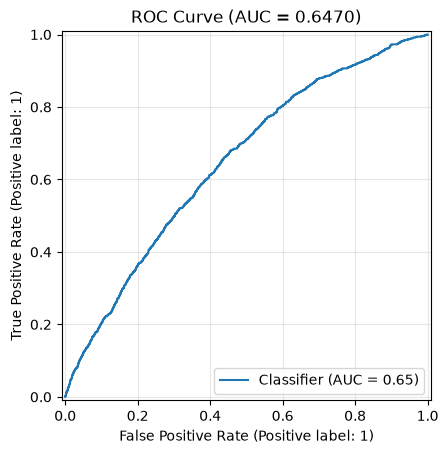

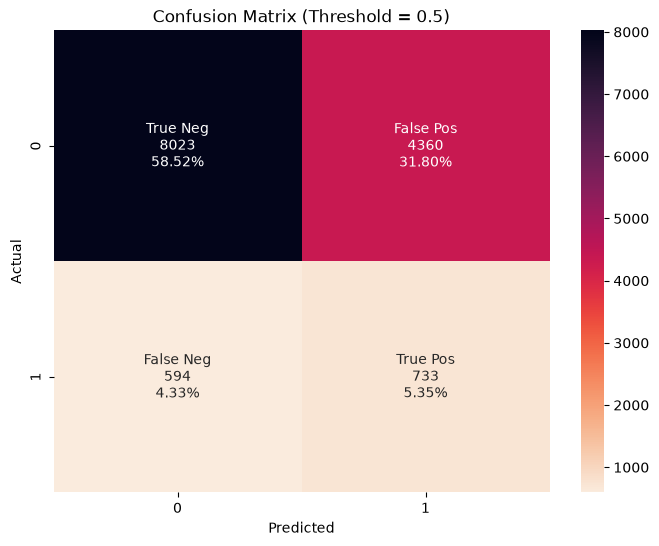


Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.65      0.76     12383
           1       0.14      0.55      0.23      1327

    accuracy                           0.64     13710
   macro avg       0.54      0.60      0.50     13710
weighted avg       0.85      0.64      0.71     13710

ROC-AUC: 0.6470433947506004
PR-AUC: 0.15635156967037384
MCC: 0.12255106991545597


In [18]:
clf, y_prob, cv_scores = train_evaluate_model(
    lgbm_clf,
    x_train,
    y_train,
    x_val,
    y_val
)

y_pred = model_evaluation(
    clf,
    x_val,
    y_val,
    threshold=0.5,
    y_prob=y_prob
)

In [19]:
importance = permutation_importance(
    clf,
    x_val,
    y_val,
    scoring="roc_auc",
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": x_val.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
}).sort_values(
    "Importance",
    ascending=False
)

display(importance_df)

,Feature,Importance,Std
4,Age (in months),0.048640,0.004006
3,Declared Number of Borrowings,0.021709,0.002734
2,Desired Credit Limit,0.018735,0.002814
0,Declared Annual Income,0.012347,0.002469
13,Residence Ownership Status,0.010885,0.002168
1,Declared Borrowing Amount,0.010327,0.002010
9,Application Channel,0.009760,0.002009
10,Company Size Category,0.009687,0.001813
12,Employment Type Category,0.005971,0.001502
5,Residence Period (in months),0.005187,0.002442


In [20]:
def feature_selection(
    X_train,
    y_train,
    model,
    top_k=None,
    importance_threshold=None
):

    # 1. Feature Selection Model
    selector_model = model
  

    # 2. Train selector
    selector_model.fit(X_train, y_train)

    # 3. Extract feature importance
    importance_df = pd.DataFrame({
        'Feature': X_train.columns,
        'Importance': selector_model.feature_importances_
    })

    importance_df = importance_df.sort_values(
        by='Importance',
        ascending=False
    ).reset_index(drop=True)

    # 4. Normalize importance
    total_importance = importance_df['Importance'].sum()

    if total_importance > 0:
        importance_df['Importance_Percent'] = (
            importance_df['Importance'] / total_importance * 100
        )
    else:
        importance_df['Importance_Percent'] = 0.0

    # 5. Select features
    if top_k is not None:

        selected_features = (
            importance_df
            .head(min(top_k, len(importance_df)))
            ['Feature']
            .tolist()
        )

    elif importance_threshold is not None:

        selected_features = (
            importance_df.loc[
                importance_df['Importance_Percent']
                >= importance_threshold,
                'Feature'
            ].tolist()
        )

    else:

        # Default: remove zero-importance features
        selected_features = (
            importance_df.loc[
                importance_df['Importance'] > 0,
                'Feature'
            ].tolist()
        )

    if len(selected_features) == 0:
        raise ValueError(
            "No features selected. Please adjust selection criteria."
        )

    # 6. Transform data
    X_train_selected = X_train[selected_features].copy()

    return (
        X_train_selected,
        selected_features,
        importance_df,
        selector_model
    )


In [21]:

X_train_selected, selected_features, importance_df, selector_model = (
    feature_selection(
        X_train=x_train,
        y_train=y_train,
        model=lgbm_clf,
        top_k=50
    )
)

X_valid_selected = x_val[selected_features].copy()

print("Original Features:", x_train.shape[1])
print("Selected Features:", len(selected_features))

print("\nSelected Features:")
print(selected_features)

print("\nFeature Importance:")
print(importance_df.head(30))


Original Features: 15
Selected Features: 15

Selected Features:
['Age (in months)', 'Declared Annual Income', 'Residence Period (in months)', 'Declared Borrowing Amount', 'Desired Credit Limit', 'Rent Burden', 'Company Size Category', 'Occupation Category', 'Industry Category', 'Declared Number of Borrowings', 'Number of Dependents', 'Employment Type Category', 'Application Channel', 'Residence Ownership Status', 'Gender']

Feature Importance:
                          Feature  Importance  Importance_Percent
0                 Age (in months)        1820           15.444671
1          Declared Annual Income        1608           13.645621
2    Residence Period (in months)        1532           13.000679
3       Declared Borrowing Amount        1040            8.825526
4            Desired Credit Limit        1040            8.825526
5                     Rent Burden         943            8.002376
6           Company Size Category         652            5.532926
7             Occupation

##

## Feature Engineering

In [22]:
def Correation(df):
    target = "12-Month Default Flag"
    corr = df.select_dtypes(
        include='number'
    ).corr(method='spearman')
    target_corr = (
        corr[target]
        .drop(target)
        .sort_values(key=abs, ascending=False)
    )
    plt.figure(figsize=(20, 10))

    sns.heatmap(
        corr,
        annot=True,
        cmap='coolwarm',
        center=0,
        fmt='.2f'
    )

    plt.title("Spearman Correlation Matrix")
    plt.tight_layout()
    plt.show()

In [23]:
def spearman_correlation(df):
    target = "12-Month Default Flag"
    corr = df.select_dtypes(
        include='number'
    ).corr(method='spearman')
    target_corr = (
        corr[target]
        .drop(target)
        .sort_values(key=abs, ascending=False)
    )

    plt.figure(figsize=(10, 8))

    sns.barplot(
        x=target_corr.values,
        y=target_corr.index
    )

    plt.title("Famale")
    plt.xlabel("Spearman Correlation")
    plt.ylabel("Features")
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()

In [24]:
from scipy import stats
from sklearn.preprocessing import PowerTransformer
pt = PowerTransformer(method='yeo-johnson')

In [25]:

import numpy as np
import pandas as pd

def Feature_engineering_func(df):

    df = df.copy()

    income = df['Declared Annual Income']
    borrowing = df['Declared Borrowing Amount']
    credit = df['Desired Credit Limit']
    num_borrowings = df['Declared Number of Borrowings']

    age = df['Age (in months)']
    residence = df['Residence Period (in months)']
    dependents = df['Number of Dependents']

    # ==================================
    # 1. Financial Indicators
    # ==================================

    df['Zero_Income_Flag'] = income.eq(0).astype(int)
    df['Zero_Borrowing_Flag'] = borrowing.eq(0).astype(int)
    df['Zero_Credit_Flag'] = credit.eq(0).astype(int)

    # ==================================
    # 2. Financial Ratios
    # ==================================

    df['Credit_Income_Ratio'] = (
        credit / income.where(income > 0)
    )

    df['Borrowing_Income_Ratio'] = (
        borrowing / income.where(income > 0)
    )

    df['Exposure_To_Income'] = (
        (borrowing + credit) / income.where(income > 0)
    )

    df['Avg_Borrowing_Per_Loan'] = (
        borrowing / num_borrowings.where(num_borrowings > 0)
    )

    df['Limit_To_Borrow'] = (
        credit / borrowing.where(borrowing > 0)
    )

    df['Rent_To_Income'] = (
        df['Rent Burden'] / income.where(income > 0)
    )

    # ==================================
    # 3. Household & Dependents
    # ==================================

    df['Income_Per_Dependent'] = (
        income / (dependents + 1)
    )

    df['Children_Share'] = (
        df['Number of Dependent Children']
        / dependents.where(dependents > 0)
    )

    # ==================================
    # 4. Residence Stability
    # ==================================

    df['Residence_Stability_Ratio'] = (
        residence / age.where(age > 0)
    )

    df['Age_When_Moved'] = age - residence

    # ==================================
    # 5. Phone Information
    # ==================================

    # ==================================
    # 6. Handle Special Cases
    # ==================================

    df.loc[
        income.eq(0) & credit.eq(0),
        'Credit_Income_Ratio'
    ] = 0

    df.loc[
        income.eq(0) & borrowing.eq(0),
        'Borrowing_Income_Ratio'
    ] = 0

    df.loc[
        borrowing.eq(0) & credit.eq(0),
        'Limit_To_Borrow'
    ] = 0

    df.loc[
        num_borrowings.eq(0) & borrowing.eq(0),
        'Avg_Borrowing_Per_Loan'
    ] = 0

    df.loc[
        income.eq(0) & borrowing.eq(0) & credit.eq(0),
        'Exposure_To_Income'
    ] = 0

    df.loc[
        income.eq(0) & df['Rent Burden'].eq(0),
        'Rent_To_Income'
    ] = 0

    # ==================================
    # 7. Numerical Cleanup
    # ==================================

    new_features = [
        'Credit_Income_Ratio',
        'Borrowing_Income_Ratio',
        'Exposure_To_Income',
        'Avg_Borrowing_Per_Loan',
        'Limit_To_Borrow',
        'Rent_To_Income',
        'Income_Per_Dependent',
        'Children_Share',
        'Residence_Stability_Ratio',
        'Age_When_Moved'
    ]

    df[new_features] = df[new_features].replace(
        [np.inf, -np.inf], np.nan
    )

    return df


# Apply Feature Engineering
df_train_engineer = Feature_engineering_func(train_data)


In [26]:
def contact_feature_func(df):

    phone_cols = [
        'Home Phone Number Available',
        'Mobile Phone Number Available',
        'Employer Phone Number Available',
        'Driver Licence Number Available'
    ]

    phone_data = df[phone_cols].apply(
        pd.to_numeric,
        errors='coerce'
    )

    features = pd.DataFrame(index=df.index)

    features['Contact_Count'] = phone_data.sum(axis=1)

    features['Contact_Completeness'] = (
        phone_data.mean(axis=1)
    )

    features['Contact_Fields_Missing_Count'] = (
        phone_data.isna().sum(axis=1)
    )

    features['Has_Personal_Contact'] = (
        phone_data[
            [
                'Home Phone Number Available',
                'Mobile Phone Number Available'
            ]
        ].max(axis=1)
    )

    return features

df_contact = contact_feature_func(df_train_engineer)

In [27]:
df_contact

,Contact_Count,Contact_Completeness,Contact_Fields_Missing_Count,Has_Personal_Contact
0,4,1.00,0,1
1,1,0.25,0,1
2,3,0.75,0,1
3,4,1.00,0,1
4,3,0.75,0,1
...,...,...,...,...
68541,3,0.75,0,1
68542,2,0.50,0,1
68543,3,0.75,0,1
68544,2,0.50,0,1


In [28]:
df_train_engineer

,ID,12-Month Default Flag,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,...,Credit_Income_Ratio,Borrowing_Income_Ratio,Exposure_To_Income,Avg_Borrowing_Per_Loan,Limit_To_Borrow,Rent_To_Income,Income_Per_Dependent,Children_Share,Residence_Stability_Ratio,Age_When_Moved
0,211880002,0,18,1,2,699,141,140,8,6,...,0.062500,0.291667,0.354167,466666.666667,0.214286,0.010417,1600000.0,0.5,0.201717,558
1,211870004,0,20,2,2,419,26,640,1,1,...,0.057143,0.171429,0.228571,150000.000000,0.333333,0.000000,1750000.0,0.0,0.062053,393
2,211930001,0,1,2,1,322,181,540,8,5,...,0.064103,0.115385,0.179487,180000.000000,0.555556,0.000000,1560000.0,NaN,0.562112,141
3,211920001,0,17,1,1,328,328,640,1,5,...,0.055556,0.277778,0.333333,250000.000000,0.200000,0.000000,1800000.0,NaN,1.000000,0
4,211880003,1,18,1,1,451,44,1040,16,1,...,0.020000,0.200000,0.220000,1000000.000000,0.100000,0.012000,5000000.0,NaN,0.097561,407
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68541,215470332,0,17,1,2,372,372,640,99,5,...,0.055556,0.027778,0.083333,100000.000000,2.000000,0.000000,1800000.0,0.0,1.000000,0
68542,215470333,0,18,2,1,362,18,640,99,5,...,0.020000,0.000000,0.020000,0.000000,NaN,0.021200,1250000.0,1.0,0.049724,344
68543,215480285,0,18,1,2,457,44,340,4,1,...,0.050000,0.283333,0.333333,850000.000000,0.176471,0.000000,2000000.0,0.5,0.096280,413
68544,215470336,0,20,1,1,293,293,640,9,4,...,0.024510,0.049020,0.073529,100000.000000,0.500000,0.000000,2040000.0,NaN,1.000000,0


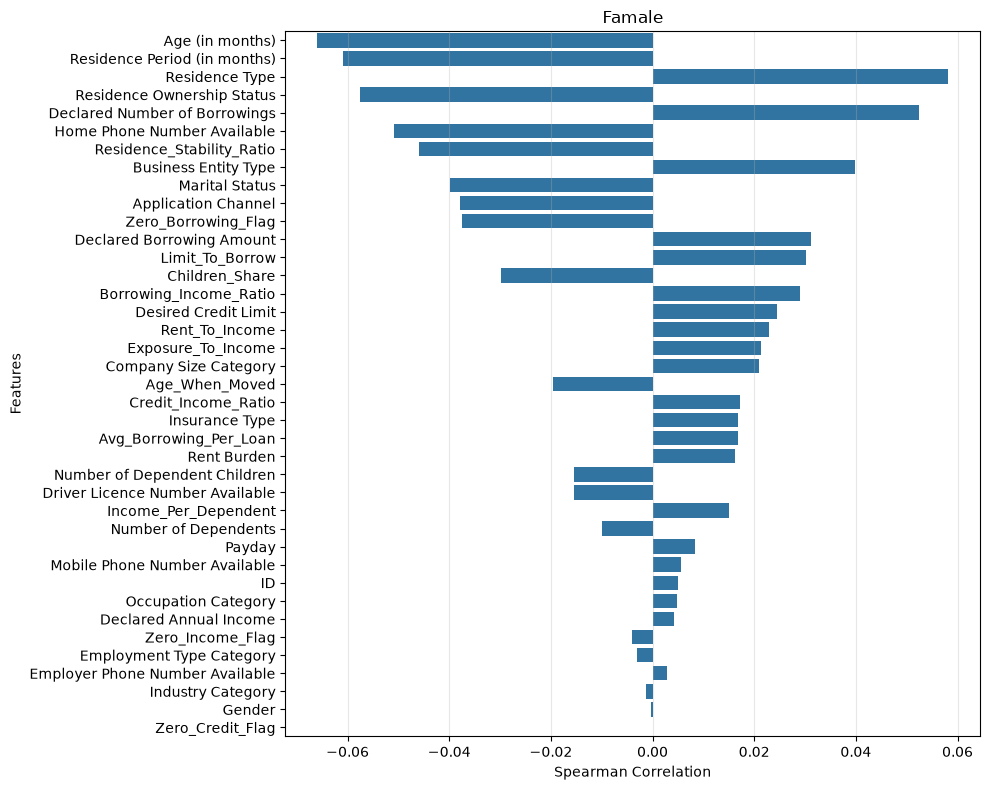

In [29]:
spearman_correlation(df_train_engineer)

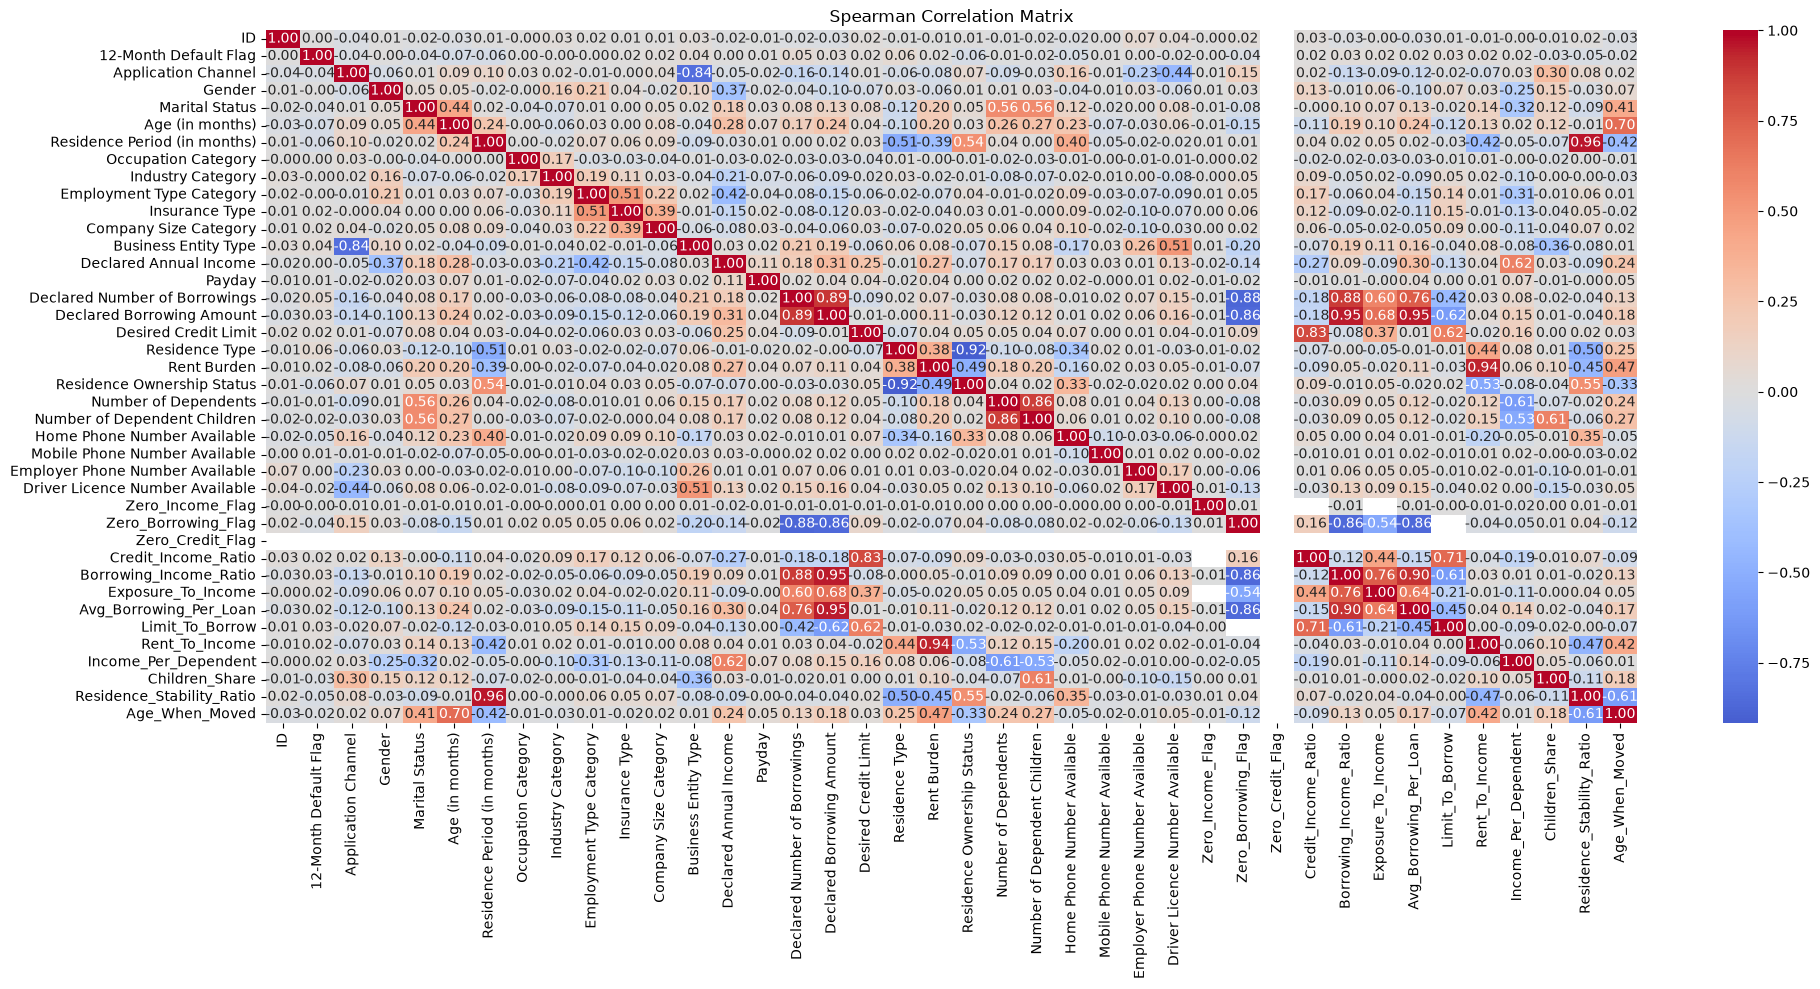

In [30]:
Correation(df_train_engineer)

In [31]:
df_train_engineer

,ID,12-Month Default Flag,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,...,Credit_Income_Ratio,Borrowing_Income_Ratio,Exposure_To_Income,Avg_Borrowing_Per_Loan,Limit_To_Borrow,Rent_To_Income,Income_Per_Dependent,Children_Share,Residence_Stability_Ratio,Age_When_Moved
0,211880002,0,18,1,2,699,141,140,8,6,...,0.062500,0.291667,0.354167,466666.666667,0.214286,0.010417,1600000.0,0.5,0.201717,558
1,211870004,0,20,2,2,419,26,640,1,1,...,0.057143,0.171429,0.228571,150000.000000,0.333333,0.000000,1750000.0,0.0,0.062053,393
2,211930001,0,1,2,1,322,181,540,8,5,...,0.064103,0.115385,0.179487,180000.000000,0.555556,0.000000,1560000.0,NaN,0.562112,141
3,211920001,0,17,1,1,328,328,640,1,5,...,0.055556,0.277778,0.333333,250000.000000,0.200000,0.000000,1800000.0,NaN,1.000000,0
4,211880003,1,18,1,1,451,44,1040,16,1,...,0.020000,0.200000,0.220000,1000000.000000,0.100000,0.012000,5000000.0,NaN,0.097561,407
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68541,215470332,0,17,1,2,372,372,640,99,5,...,0.055556,0.027778,0.083333,100000.000000,2.000000,0.000000,1800000.0,0.0,1.000000,0
68542,215470333,0,18,2,1,362,18,640,99,5,...,0.020000,0.000000,0.020000,0.000000,NaN,0.021200,1250000.0,1.0,0.049724,344
68543,215480285,0,18,1,2,457,44,340,4,1,...,0.050000,0.283333,0.333333,850000.000000,0.176471,0.000000,2000000.0,0.5,0.096280,413
68544,215470336,0,20,1,1,293,293,640,9,4,...,0.024510,0.049020,0.073529,100000.000000,0.500000,0.000000,2040000.0,NaN,1.000000,0


In [32]:
missing_df = pd.DataFrame({
    'Missing_Count': df_train_engineer.isna().sum(),
    'Missing_Percent': df_train_engineer.isna().mean() * 100
})

missing_df = missing_df.sort_values(
    by='Missing_Count',
    ascending=False
)

display(missing_df)

,Missing_Count,Missing_Percent
Children_Share,47589,69.426371
Limit_To_Borrow,25340,36.967876
Credit_Income_Ratio,10,0.014589
Exposure_To_Income,10,0.014589
Borrowing_Income_Ratio,4,0.005835
Rent_To_Income,2,0.002918
Zero_Income_Flag,0,0.000000
Number of Dependent Children,0,0.000000
Home Phone Number Available,0,0.000000
Mobile Phone Number Available,0,0.000000


In [33]:
"""
feature_eninfunc = [
        "Declared Annual Income",
        "Declared Borrowing Amount",
        "Desired Credit Limit",
        "Declared Number of Borrowings",
        "Age (in months)",
        "Residence Period (in months)",
        "Rent Burden",
        "Occupation Category",
        "Industry Category",
        "Application Channel",
        "Company Size Category",
        "Number of Dependents",
        "Employment Type Category",#..
        "Residence Ownership Status",

        #================
        "Marital Status",
        "Number of Dependent Children",
        "Gender",

        "Income_Per_Dependent",
        "Residence_Stability_Ratio",
        "Borrowing_Income_Ratio",
        "Avg_Borrowing_Per_Loan"
        #"Gender_x_Insurance",
        #"Business_vs_sizecompany(en)"
]
"""
feature_engineerfunc = [
        'Credit_Income_Ratio',
        'Borrowing_Income_Ratio',
        'Exposure_To_Income',
        'Avg_Borrowing_Per_Loan',
        'Limit_To_Borrow',
        'Rent_To_Income',
        'Income_Per_Dependent',
        'Children_Share',
        'Residence_Stability_Ratio',
        'Age_When_Moved'
]

In [34]:
feature_engineer_of_model = feature_firstset + feature_engineerfunc

In [35]:
print(len(feature_firstset))
print(len(feature_engineer_of_model))

15
25


In [36]:
type(feature_engineerfunc)

list

In [37]:
x_train, x_val, y_train, y_val = Set_up_data_sendmodel(df_train_engineer,feature_engineer_of_model)

Train: (54836, 25) (54836,)
Validation: (13710, 25) (13710,)

Train Distribution:
0    0.903239
1    0.096761
Name: proportion, dtype: float64

Validation Distribution:
0    0.903209
1    0.096791
Name: proportion, dtype: float64


In [38]:
lgbm_clf_en = LGBMClassifier(
    n_estimators=400,
    learning_rate=0.025,

    max_depth=5,
    num_leaves=16,

    min_child_samples=100,
    min_child_weight=1e-2,
    min_split_gain=0.02,

    subsample=0.80,
    subsample_freq=1,
    colsample_bytree=0.75,

    reg_alpha=0.5,
    reg_lambda=5.0,

    class_weight='balanced',

    n_jobs=-1,
    verbose=-1,
)

xgb_clf = XGBClassifier(
    n_estimators=400,
    learning_rate=0.025,

    # Tree architecture
    max_depth=5,
    max_leaves=16,
    grow_policy='lossguide', # สำคัญ: สั่งให้ XGBoost แตกกิ่งแบบ Leaf-wise เหมือน LightGBM

    # Regularization & Pruning
    min_child_weight=5, # XGBoost ใช้ Hessian weight (ปรับชดเชยแทน min_child_samples=100)
    gamma=0.02, # เทียบเท่า min_split_gain

    # Sampling
    subsample=0.80,
    colsample_bytree=0.75,

    # L1/L2 Regularization
    reg_alpha=0.5,
    reg_lambda=5.0,

    # Imbalance Handling
    scale_pos_weight=9.33, # เทียบเท่า class_weight='balanced'

    # System
    n_jobs=-1,
    random_state=42,
    eval_metric='auc' 
)

In [39]:
lgbm_clf_en.get_params

<bound method LGBMModel.get_params of LGBMClassifier(class_weight='balanced', colsample_bytree=0.75,
               learning_rate=0.025, max_depth=5, min_child_samples=100,
               min_child_weight=0.01, min_split_gain=0.02, n_estimators=400,
               n_jobs=-1, num_leaves=16, reg_alpha=0.5, reg_lambda=5.0,
               subsample=0.8, subsample_freq=1, verbose=-1)>

CV ROC-AUC: 0.6405
CV STD: 0.0081

Validation ROC-AUC: 0.6503
Validation PR-AUC: 0.1579


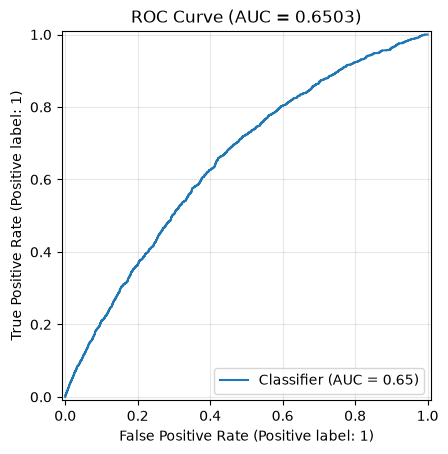

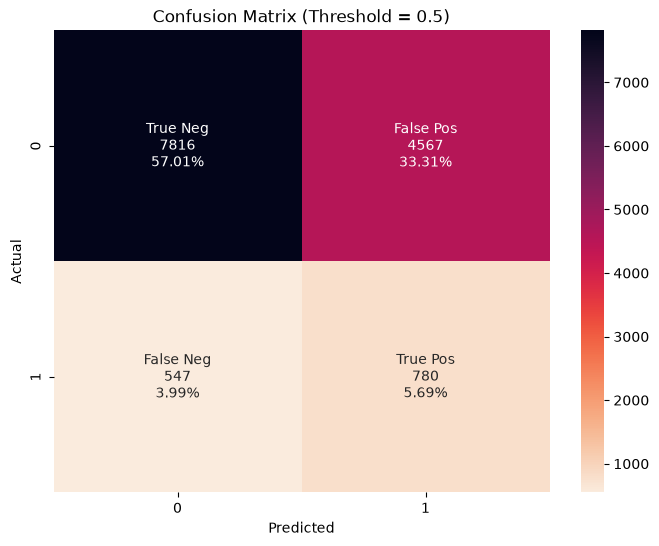


Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.63      0.75     12383
           1       0.15      0.59      0.23      1327

    accuracy                           0.63     13710
   macro avg       0.54      0.61      0.49     13710
weighted avg       0.86      0.63      0.70     13710

ROC-AUC: 0.6502808107549056
PR-AUC: 0.15791986719435674
MCC: 0.1327445109986449


In [40]:
clf_en, y_prob_en, cv_scores_en = train_evaluate_model(
    lgbm_clf_en,
    x_train,
    y_train,
    x_val,
    y_val
)

y_pred_en = model_evaluation(
    clf_en,
    x_val,
    y_val,
    threshold=0.5,
    y_prob=y_prob_en
)

In [41]:
importance = permutation_importance(
    clf_en,
    x_val,
    y_val,
    scoring="roc_auc",
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": x_val.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
}).sort_values(
    "Importance",
    ascending=False
)

display(importance_df)

,Feature,Importance,Std
4,Age (in months),0.036663,0.003160
3,Declared Number of Borrowings,0.019836,0.002626
0,Declared Annual Income,0.011098,0.002663
13,Residence Ownership Status,0.010617,0.002188
9,Application Channel,0.009191,0.001693
10,Company Size Category,0.009156,0.001570
19,Limit_To_Borrow,0.005124,0.001239
12,Employment Type Category,0.004582,0.001274
15,Credit_Income_Ratio,0.003499,0.001258
17,Exposure_To_Income,0.003181,0.001180


In [42]:

X_train_selected, selected_features, importance_df, selector_model = (
    feature_selection(
        X_train=x_train,
        y_train=y_train,
        model=lgbm_clf_en,
        top_k=50
    )
)

X_valid_selected = x_val[selected_features].copy()

print("Original Features:", x_train.shape[1])
print("Selected Features:", len(selected_features))

print("\nSelected Features:")
print(selected_features)

print("\nFeature Importance:")
print(importance_df.head(30))


Original Features: 25
Selected Features: 25

Selected Features:
['Age (in months)', 'Exposure_To_Income', 'Declared Annual Income', 'Age_When_Moved', 'Residence Period (in months)', 'Credit_Income_Ratio', 'Income_Per_Dependent', 'Limit_To_Borrow', 'Company Size Category', 'Rent Burden', 'Residence_Stability_Ratio', 'Borrowing_Income_Ratio', 'Occupation Category', 'Rent_To_Income', 'Declared Number of Borrowings', 'Avg_Borrowing_Per_Loan', 'Application Channel', 'Desired Credit Limit', 'Employment Type Category', 'Industry Category', 'Declared Borrowing Amount', 'Children_Share', 'Residence Ownership Status', 'Number of Dependents', 'Gender']

Feature Importance:
                          Feature  Importance  Importance_Percent
0                 Age (in months)         571            9.734061
1              Exposure_To_Income         437            7.449710
2          Declared Annual Income         435            7.415615
3                  Age_When_Moved         340            5.796113

##

## Big feature engineer

In [43]:
feature_Big_engineer = [
       '12-Month Default Flag','Application Channel', 'Gender',
       'Marital Status', 'Age (in months)', 'Residence Period (in months)',
       'Occupation Category', 'Industry Category', 'Employment Type Category',
       'Insurance Type', 'Company Size Category', 'Business Entity Type',
       'Declared Annual Income', 'Payday', 'Declared Number of Borrowings',
       'Declared Borrowing Amount', 'Desired Credit Limit', 'Residence Type',
       'Rent Burden', 'Residence Ownership Status', 'Number of Dependents',
       'Number of Dependent Children', 'Home Phone Number Available',
       'Mobile Phone Number Available', 'Employer Phone Number Available',
       'Driver Licence Number Available'
    
]

In [44]:
# ==========================================
# 1. ORIGINAL FEATURES
# ==========================================

def original_feature_func(df):

    income = df['Declared Annual Income']
    borrowing = df['Declared Borrowing Amount']
    credit = df['Desired Credit Limit']
    num_borrowings = df['Declared Number of Borrowings']

    age = df['Age (in months)']
    residence = df['Residence Period (in months)']
    dependents = df['Number of Dependents']

    rent = df['Rent Burden']

    features = pd.DataFrame(index=df.index)

    features['Zero_Income_Flag'] = income.eq(0).astype('int8')
    features['Zero_Borrowing_Flag'] = borrowing.eq(0).astype('int8')
    features['Zero_Credit_Flag'] = credit.eq(0).astype('int8')

    features['Credit_Income_Ratio'] = (
        credit / income.where(income > 0)
    )

    features['Borrowing_Income_Ratio'] = (
        borrowing / income.where(income > 0)
    )

    features['Exposure_To_Income'] = (
        (borrowing + credit) / income.where(income > 0)
    )

    features['Avg_Borrowing_Per_Loan'] = (
        borrowing / num_borrowings.where(num_borrowings > 0)
    )

    features['Limit_To_Borrow'] = (
        credit / borrowing.where(borrowing > 0)
    )

    features['Rent_To_Income'] = (
        rent / income.where(income > 0)
    )

    features['Income_Per_Dependent'] = (
        income / (dependents + 1)
    )

    features['Children_Share'] = (
        df['Number of Dependent Children']
        / dependents.where(dependents > 0)
    )

    features['Residence_Stability_Ratio'] = (
        residence / age.where(age > 0)
    )

    features['Age_When_Moved'] = age - residence

    # Special cases
    features.loc[
        income.eq(0) & credit.eq(0),
        'Credit_Income_Ratio'
    ] = 0

    features.loc[
        income.eq(0) & borrowing.eq(0),
        'Borrowing_Income_Ratio'
    ] = 0

    features.loc[
        borrowing.eq(0) & credit.eq(0),
        'Limit_To_Borrow'
    ] = 0

    features.loc[
        num_borrowings.eq(0) & borrowing.eq(0),
        'Avg_Borrowing_Per_Loan'
    ] = 0

    features.loc[
        income.eq(0) & borrowing.eq(0) & credit.eq(0),
        'Exposure_To_Income'
    ] = 0

    features.loc[
        income.eq(0) & rent.eq(0),
        'Rent_To_Income'
    ] = 0

    return features.replace([np.inf, -np.inf], np.nan)


# ==========================================
# 2. FINANCIAL FEATURES
# ==========================================

def financial_feature_func(df):

    income = df['Declared Annual Income']
    borrowing = df['Declared Borrowing Amount']
    rent = df['Rent Burden']
    num_borrowings = df['Declared Number of Borrowings']
    dependents = df['Number of Dependents']

    features = pd.DataFrame(index=df.index)

    features['Total_Burden_Ratio'] = (
        (borrowing + rent) / income.where(income > 0)
    )

    features['Net_Income_After_Rent'] = (
        income - rent
    )

    features['Net_Income_Per_Dependent'] = (
        (income - rent) / (dependents + 1)
    )

    features['Debt_Per_Dependent'] = (
        borrowing / (dependents + 1)
    )

    features['Rent_Per_Dependent'] = (
        rent / (dependents + 1)
    )

    features['Income_Per_Loan'] = (
        income / num_borrowings.where(num_borrowings > 0)
    )

    return features.replace([np.inf, -np.inf], np.nan)


# ==========================================
# 3. CONTACT FEATURES
# ==========================================

def contact_feature_func(df):

    phone_cols = [
        'Home Phone Number Available',
        'Mobile Phone Number Available',
        'Employer Phone Number Available',
        'Driver Licence Number Available'
    ]

    phone_data = df[phone_cols].apply(
        pd.to_numeric,
        errors='coerce'
    )

    features = pd.DataFrame(index=df.index)

    features['Contact_Count'] = phone_data.sum(axis=1)

    features['Contact_Completeness'] = (
        phone_data.mean(axis=1)
    )

    features['Contact_Fields_Missing_Count'] = (
        phone_data.isna().sum(axis=1)
    )

    features['Has_Personal_Contact'] = (
        phone_data[
            [
                'Home Phone Number Available',
                'Mobile Phone Number Available'
            ]
        ].max(axis=1)
    )

    return features


# ==========================================
# 4. INTERACTION FEATURES
# ==========================================

def interaction_feature_func(df):

    features = pd.DataFrame(index=df.index)

    interaction_pairs = [
        (
            'Employment Type Category',
            'Company Size Category', # Company type data
            'Employment_Company_Interaction'
        ),
        (
            'Industry Category',
            'Business Entity Type', #
            'Industry_Business_Interaction'
        ),
        (
            'Occupation Category',
            'Employment Type Category',
            'Occupation_Employment_Interaction'
        )
    ]

    for col1, col2, new_col in interaction_pairs:

        features[new_col] = (
            df[col1].astype('string').fillna('__MISSING__')
            + '_'
            + df[col2].astype('string').fillna('__MISSING__')
        ).astype('category')

    return features


# ==========================================
# 5. MISSING FEATURES
# ==========================================

def missing_feature_func(df):

    missing_cols = [
        'Declared Annual Income',
        'Declared Borrowing Amount',
        'Desired Credit Limit',
        'Declared Number of Borrowings',
        'Rent Burden',
        'Age (in months)',
        'Residence Period (in months)',
        'Number of Dependents',
        'Number of Dependent Children'
    ]

    features = pd.DataFrame(index=df.index)

    for col in missing_cols:

        features[f'{col}_Missing'] = (
            df[col].isna().astype('int8')
        )

    return features


# ==========================================
# 6. LOG FEATURES
# ==========================================

def log_feature_func(df):

    log_cols = [
        'Declared Annual Income',
        'Declared Borrowing Amount',
        'Desired Credit Limit',
        'Rent Burden',
        'Declared Number of Borrowings'
    ]

    features = pd.DataFrame(index=df.index)

    for col in log_cols:

        features[f'{col}_Log1p'] = np.log1p(
            df[col].clip(lower=0)
        )

    return features.replace([np.inf, -np.inf], np.nan)

# ==============================================
# 7. Frequency Encoding
# ==============================================

def frequency_encoding_func(fit_df, transform_df=None):

    transform_df = fit_df
    features = pd.DataFrame(index=transform_df.index)

    # ----------------------------------
    # 1. BASIC FREQUENCY + RARITY
    # ----------------------------------

    single_cols = [
        'Company Size Category',
        'Occupation Category',
        'Application Channel',
        'Employment Type Category',
        'Industry Category',
        'Business Entity Type'
    ]

    missing_token = '__MISSING__'

    def normalize_col(df, col):
        return df[col].astype(object).where(
            df[col].notna(), missing_token
        )

    for col in single_cols:

        train_values = normalize_col(fit_df, col)
        test_values = normalize_col(transform_df, col)

        freq_map = train_values.value_counts(
            normalize=True,
            dropna=False
        ).to_dict()

        freq = test_values.map(freq_map).fillna(0)

        features[f'{col}_freq'] = freq
        features[f'{col}_rarity'] = -np.log(
            freq.clip(lower=1e-10)
        )

    # ----------------------------------
    # 2. JOINT + CONDITIONAL FREQUENCY
    # ----------------------------------

    pairs = [
        (
            'Employment Type Category',
            'Company Size Category',
            'Employment_Company'
        ),
        (
            'Occupation Category',
            'Employment Type Category',
            'Occupation_Employment'
        ),
        (
            'Industry Category',
            'Business Entity Type',
            'Industry_Entity'
        ),
        (
            'Company Size Category',
            'Occupation Category',
            'Company_Occupation'
        )
    ]

    for col1, col2, name in pairs:

        train_a = normalize_col(fit_df, col1)
        train_b = normalize_col(fit_df, col2)

        test_a = normalize_col(transform_df, col1)
        test_b = normalize_col(transform_df, col2)

        train_pairs = list(zip(train_a, train_b))
        test_pairs = list(zip(test_a, test_b))

        # Joint Frequency: P(A, B)
        joint_counts = pd.Series(
            train_pairs
        ).value_counts()

        joint_map = (
            joint_counts / len(fit_df)
        ).to_dict()

        features[f'{name}_joint_freq'] = (
            pd.Series(test_pairs, index=transform_df.index)
            .map(joint_map)
            .fillna(0)
        )

        # Conditional Frequency: P(A | B)
        context_counts = train_b.value_counts().to_dict()

        conditional_map = {
            pair: count / context_counts[pair[1]]
            for pair, count in joint_counts.items()
        }

        features[f'{name}_conditional_freq'] = (
            pd.Series(test_pairs, index=transform_df.index)
            .map(conditional_map)
            .fillna(0)
        )

    return features



# ==============================================
# 7. Gender interaction
# ==============================================
#def Gender_interaction_func(df):
    


In [45]:

def build_features(
    df,
    groups=None,
    baseline_features=None
):

    if groups is None:
        groups = [
            'original',
            'financial',
            'contact',
            'interaction',
            'missing',
            'log'
        ]

    feature_functions = {
        'original': original_feature_func,
        'financial': financial_feature_func,
        'contact': contact_feature_func,
        'interaction': interaction_feature_func,
        'missing': missing_feature_func,
        'log': log_feature_func,
        'freq': frequency_encoding_func
    }

    result = []

    # Original dataset features
    if baseline_features is not None:
        result.append(df[baseline_features].copy())

    # Selected engineered features
    for group in groups:

        if group not in feature_functions:
            raise ValueError(
                f"Unknown feature group: {group}"
            )

        group_features = feature_functions[group](df)

        result.append(group_features)

    if len(result) == 0:
        return pd.DataFrame(index=df.index)

    X = pd.concat(result, axis=1)

    # Prevent duplicated column names
    if X.columns.duplicated().any():
        duplicates = X.columns[X.columns.duplicated()].tolist()
        raise ValueError(f"Duplicate features: {duplicates}")

    return X


In [46]:

# ==========================================
# FEATURE GROUP DEFINITIONS
# ==========================================

ORIGINAL_FEATURES = [
    'Zero_Income_Flag',
    'Zero_Borrowing_Flag',
    'Zero_Credit_Flag',

    'Credit_Income_Ratio',
    'Borrowing_Income_Ratio',
    'Exposure_To_Income',
    'Avg_Borrowing_Per_Loan',
    'Limit_To_Borrow',
    'Rent_To_Income',

    'Income_Per_Dependent',
    'Children_Share',

    'Residence_Stability_Ratio',
    'Age_When_Moved'
]


FINANCIAL_FEATURES = [
    'Total_Burden_Ratio',
    'Net_Income_After_Rent',
    'Net_Income_Per_Dependent',
    'Debt_Per_Dependent',
    'Rent_Per_Dependent',
    'Income_Per_Loan'
]


CONTACT_FEATURES = [
    'Contact_Count',
    'Contact_Completeness',
    'Contact_Fields_Missing_Count',
    'Has_Personal_Contact'
]


INTERACTION_FEATURES = [
    'Employment_Company_Interaction',
    'Industry_Business_Interaction',
    'Occupation_Employment_Interaction'
]


MISSING_FEATURES = [
    'Declared Annual Income_Missing',
    'Declared Borrowing Amount_Missing',
    'Desired Credit Limit_Missing',
    'Declared Number of Borrowings_Missing',
    'Rent Burden_Missing',
    'Age (in months)_Missing',
    'Residence Period (in months)_Missing',
    'Number of Dependents_Missing',
    'Number of Dependent Children_Missing'
]


LOG_FEATURES = [
    'Declared Annual Income_Log1p',
    'Declared Borrowing Amount_Log1p',
    'Desired Credit Limit_Log1p',
    'Rent Burden_Log1p',
    'Declared Number of Borrowings_Log1p'
]


In [47]:
EXPERIMENTS = {

    'baseline': [],

    'original': [
        'original'
    ],

    'financial': [
        'original',
        'financial'
    ],

    'contact': [
        'original',
        'contact'
    ],

    'interaction': [
        'original',
        'interaction'
    ],

    'financial_contact': [
        'original',
        'financial',
        'contact'
    ],

    'all_features': [
        'original',
        'financial',
        'contact',
        'interaction',
        'missing',
        'log'
    ],

    'financial_frequency':[
        'original',
        'financial',
        'freq',
        'interaction',
    ]
}


X_experiments = {
    name: build_features(
        train_data,
        groups=groups,
        baseline_features=feature_Big_engineer
    )
    for name, groups in EXPERIMENTS.items()
}


# Inspect feature counts
for name, X in X_experiments.items():

    print(
        f'{name:25s} | '
        f'Features: {X.shape[1]} | '
        f'Shape: {X.shape}'
    )



baseline                  | Features: 26 | Shape: (68546, 26)
original                  | Features: 39 | Shape: (68546, 39)
financial                 | Features: 45 | Shape: (68546, 45)
contact                   | Features: 43 | Shape: (68546, 43)
interaction               | Features: 42 | Shape: (68546, 42)
financial_contact         | Features: 49 | Shape: (68546, 49)
all_features              | Features: 66 | Shape: (68546, 66)
financial_frequency       | Features: 68 | Shape: (68546, 68)


In [48]:
feature = X_experiments['baseline'].columns
feature = list(feature)
feature

['12-Month Default Flag',
 'Application Channel',
 'Gender',
 'Marital Status',
 'Age (in months)',
 'Residence Period (in months)',
 'Occupation Category',
 'Industry Category',
 'Employment Type Category',
 'Insurance Type',
 'Company Size Category',
 'Business Entity Type',
 'Declared Annual Income',
 'Payday',
 'Declared Number of Borrowings',
 'Declared Borrowing Amount',
 'Desired Credit Limit',
 'Residence Type',
 'Rent Burden',
 'Residence Ownership Status',
 'Number of Dependents',
 'Number of Dependent Children',
 'Home Phone Number Available',
 'Mobile Phone Number Available',
 'Employer Phone Number Available',
 'Driver Licence Number Available']

##

##

##

#### =======================
#### XGBoostClassify model
#### =======================

The title model is: baseline
Train: (54836, 25) (54836,)
Validation: (13710, 25) (13710,)

Train Distribution:
0    0.903239
1    0.096761
Name: proportion, dtype: float64

Validation Distribution:
0    0.903209
1    0.096791
Name: proportion, dtype: float64
(54836, 25)

CV ROC-AUC: 0.6453
CV STD: 0.0076

Validation ROC-AUC: 0.6568
Validation PR-AUC: 0.1652


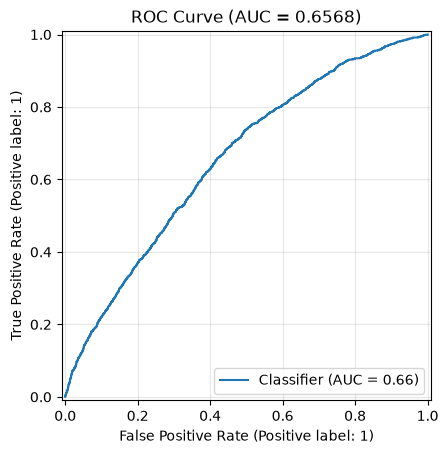

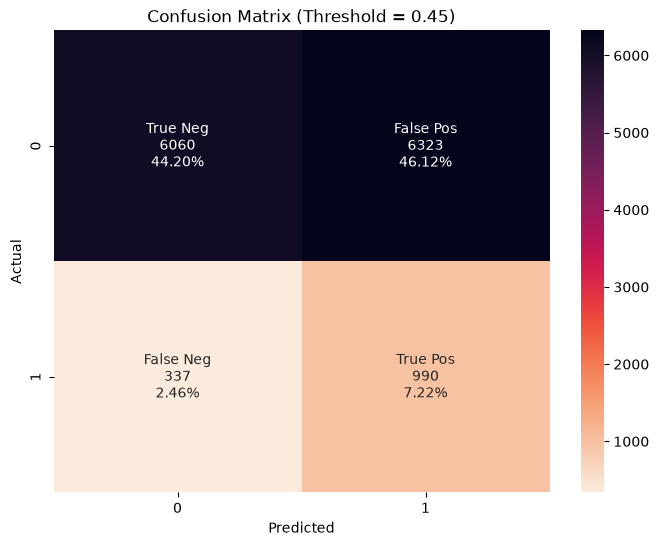


Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.49      0.65     12383
           1       0.14      0.75      0.23      1327

    accuracy                           0.51     13710
   macro avg       0.54      0.62      0.44     13710
weighted avg       0.87      0.51      0.61     13710

ROC-AUC: 0.656783940790547
PR-AUC: 0.16523520679076403
MCC: 0.13952876240835307
CV mean: [0.65290144 0.63571079 0.65472258 0.63297451 0.65195871 0.64507795
 0.65050385 0.64932419 0.64520674 0.63510809]

The title model is: original
Train: (54836, 38) (54836,)
Validation: (13710, 38) (13710,)

Train Distribution:
0    0.903239
1    0.096761
Name: proportion, dtype: float64

Validation Distribution:
0    0.903209
1    0.096791
Name: proportion, dtype: float64
(54836, 38)

CV ROC-AUC: 0.6434
CV STD: 0.0068

Validation ROC-AUC: 0.6585
Validation PR-AUC: 0.1644


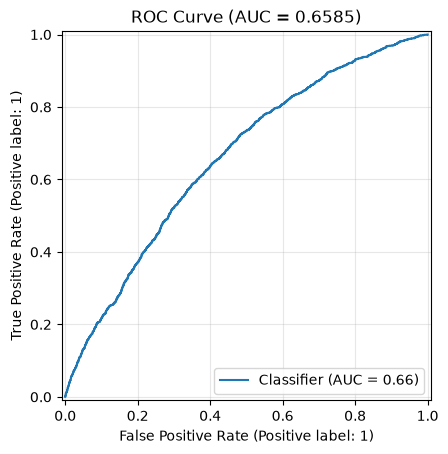

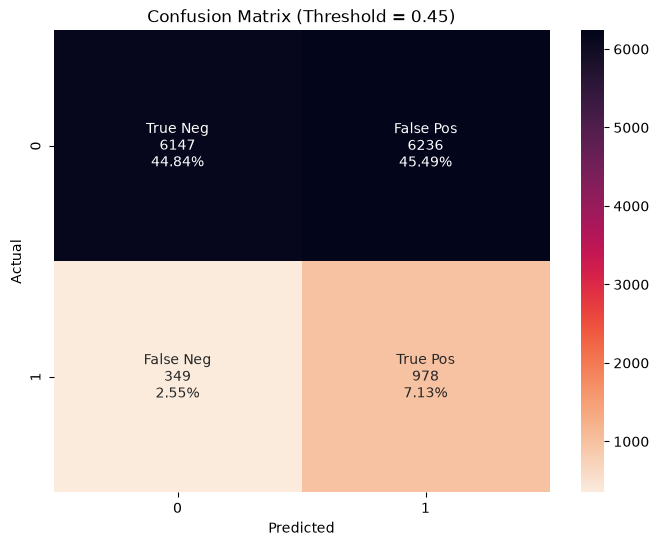


Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.50      0.65     12383
           1       0.14      0.74      0.23      1327

    accuracy                           0.52     13710
   macro avg       0.54      0.62      0.44     13710
weighted avg       0.87      0.52      0.61     13710

ROC-AUC: 0.658467642970913
PR-AUC: 0.16440928000600477
MCC: 0.1382138025161595
CV mean: [0.65457452 0.63467014 0.64743747 0.63424513 0.6505529  0.64671481
 0.64190687 0.64610244 0.64395164 0.63399628]

The title model is: financial
Train: (54836, 44) (54836,)
Validation: (13710, 44) (13710,)

Train Distribution:
0    0.903239
1    0.096761
Name: proportion, dtype: float64

Validation Distribution:
0    0.903209
1    0.096791
Name: proportion, dtype: float64
(54836, 44)

CV ROC-AUC: 0.6446
CV STD: 0.0071

Validation ROC-AUC: 0.6574
Validation PR-AUC: 0.1632


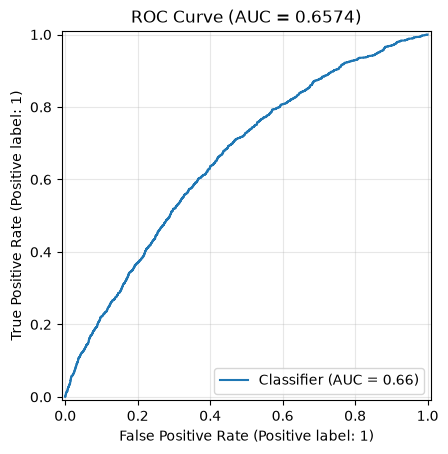

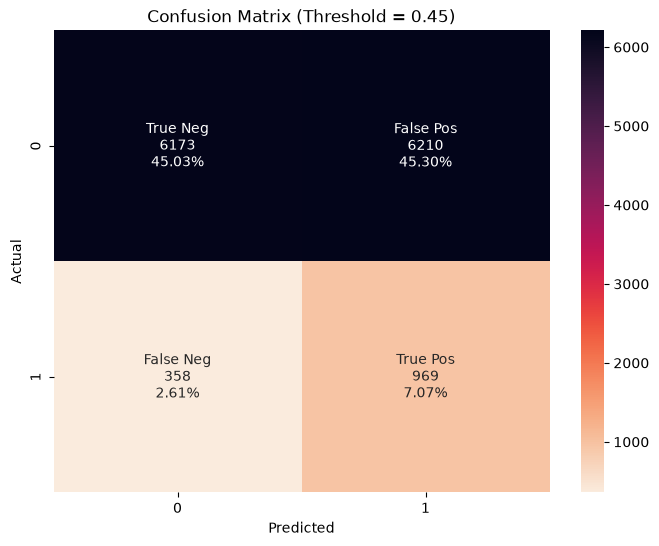


Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.50      0.65     12383
           1       0.13      0.73      0.23      1327

    accuracy                           0.52     13710
   macro avg       0.54      0.61      0.44     13710
weighted avg       0.87      0.52      0.61     13710

ROC-AUC: 0.6573815160086808
PR-AUC: 0.16315231161470461
MCC: 0.13540645538822982
CV mean: [0.6571788  0.63544429 0.65016176 0.63507993 0.65149602 0.64517011
 0.64416524 0.6466236  0.64549722 0.63535276]

The title model is: contact
Train: (54836, 42) (54836,)
Validation: (13710, 42) (13710,)

Train Distribution:
0    0.903239
1    0.096761
Name: proportion, dtype: float64

Validation Distribution:
0    0.903209
1    0.096791
Name: proportion, dtype: float64
(54836, 42)

CV ROC-AUC: 0.6443
CV STD: 0.0070

Validation ROC-AUC: 0.6554
Validation PR-AUC: 0.1629


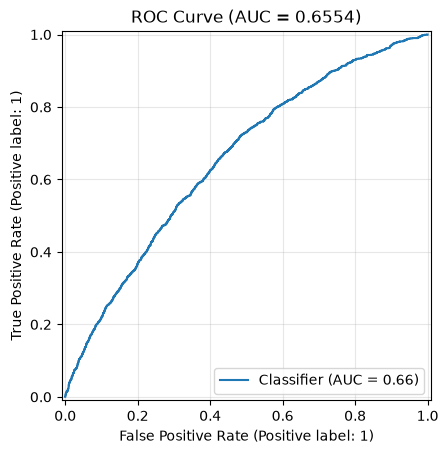

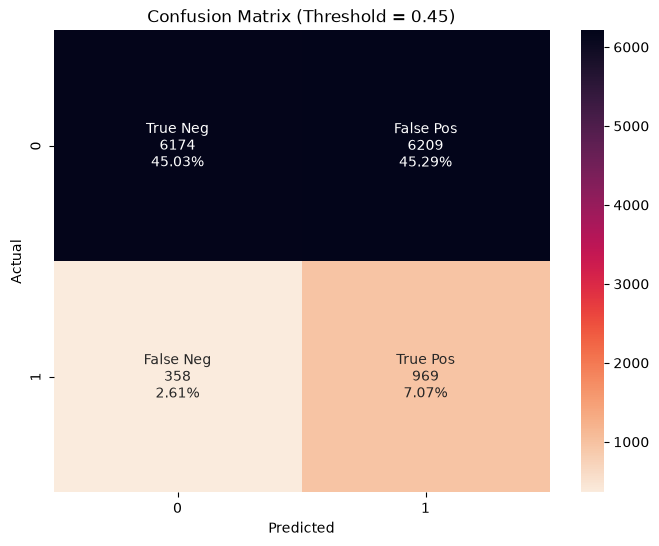


Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.50      0.65     12383
           1       0.13      0.73      0.23      1327

    accuracy                           0.52     13710
   macro avg       0.54      0.61      0.44     13710
weighted avg       0.87      0.52      0.61     13710

ROC-AUC: 0.6554188196241767
PR-AUC: 0.16286857815713734
MCC: 0.13545332881755373
CV mean: [0.65590596 0.63638718 0.64960658 0.63393933 0.65108742 0.64631358
 0.64257641 0.64537739 0.64719252 0.63448527]

The title model is: interaction
Train: (54836, 41) (54836,)
Validation: (13710, 41) (13710,)

Train Distribution:
0    0.903239
1    0.096761
Name: proportion, dtype: float64

Validation Distribution:
0    0.903209
1    0.096791
Name: proportion, dtype: float64
(54836, 41)

CV ROC-AUC: 0.6249
CV STD: 0.0096

Validation ROC-AUC: 0.6434
Validation PR-AUC: 0.1594


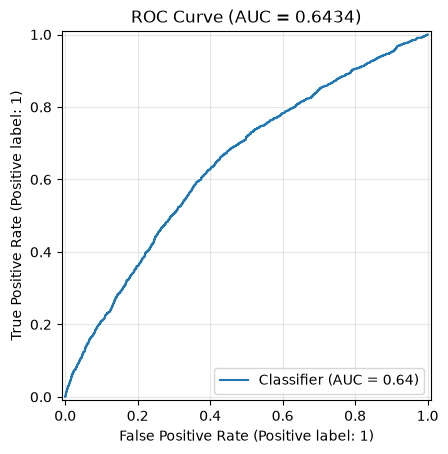

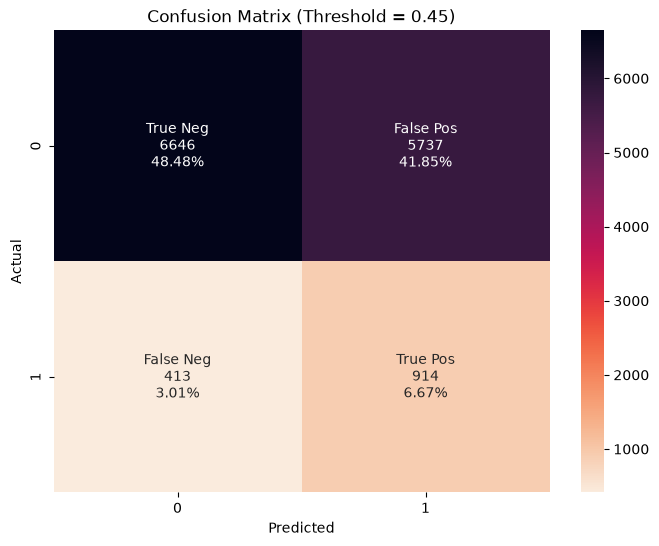


Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.54      0.68     12383
           1       0.14      0.69      0.23      1327

    accuracy                           0.55     13710
   macro avg       0.54      0.61      0.46     13710
weighted avg       0.86      0.55      0.64     13710

ROC-AUC: 0.6433605130304503
PR-AUC: 0.15939007742204692
MCC: 0.13339272182829956
CV mean: [0.64296948 0.61109781 0.62237887 0.61962005 0.64018889 0.61682461
 0.62187227 0.62810818 0.62715554 0.61848197]

The title model is: financial_contact
Train: (54836, 48) (54836,)
Validation: (13710, 48) (13710,)

Train Distribution:
0    0.903239
1    0.096761
Name: proportion, dtype: float64

Validation Distribution:
0    0.903209
1    0.096791
Name: proportion, dtype: float64
(54836, 48)

CV ROC-AUC: 0.6449
CV STD: 0.0075

Validation ROC-AUC: 0.6568
Validation PR-AUC: 0.1633


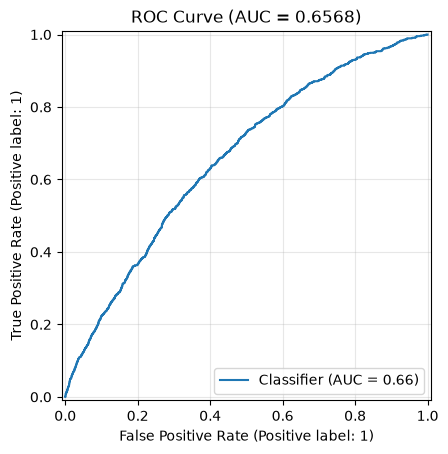

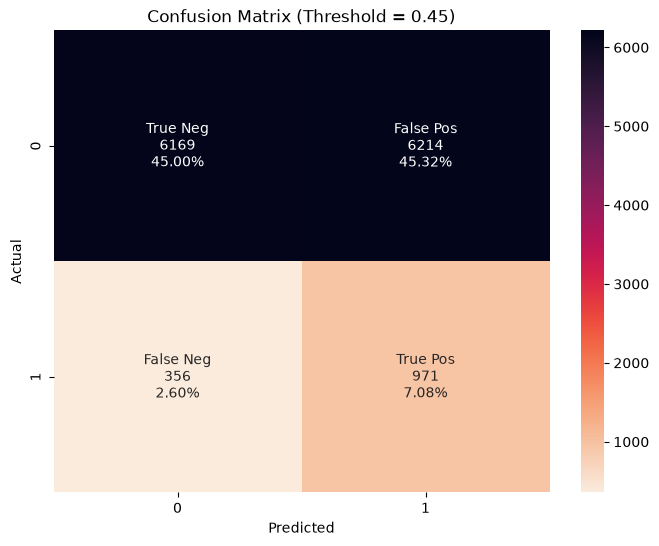


Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.50      0.65     12383
           1       0.14      0.73      0.23      1327

    accuracy                           0.52     13710
   macro avg       0.54      0.61      0.44     13710
weighted avg       0.87      0.52      0.61     13710

ROC-AUC: 0.6567992156395467
PR-AUC: 0.16330742707465257
MCC: 0.13611316740181784
CV mean: [0.65765702 0.63405841 0.65042393 0.63540742 0.65045661 0.64663667
 0.64270576 0.64854205 0.64792903 0.6352147 ]

The title model is: all_features
Train: (54836, 65) (54836,)
Validation: (13710, 65) (13710,)

Train Distribution:
0    0.903239
1    0.096761
Name: proportion, dtype: float64

Validation Distribution:
0    0.903209
1    0.096791
Name: proportion, dtype: float64
(54836, 65)

CV ROC-AUC: 0.6243
CV STD: 0.0100

Validation ROC-AUC: 0.6457
Validation PR-AUC: 0.1588


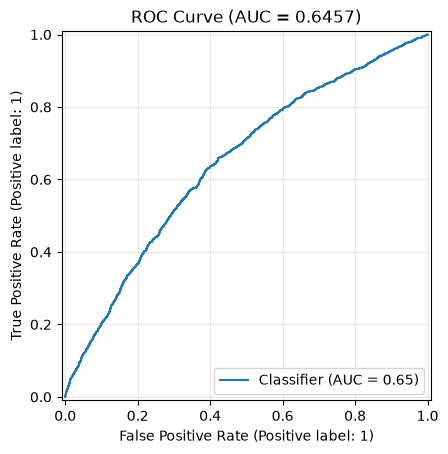

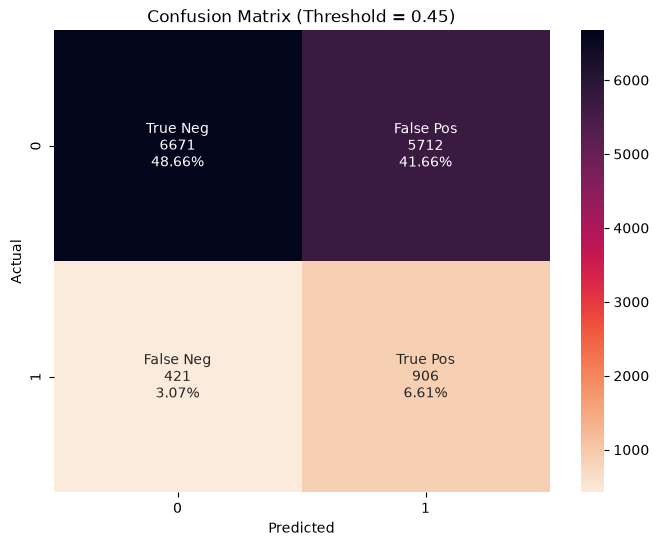


Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.54      0.69     12383
           1       0.14      0.68      0.23      1327

    accuracy                           0.55     13710
   macro avg       0.54      0.61      0.46     13710
weighted avg       0.86      0.55      0.64     13710

ROC-AUC: 0.645653961623372
PR-AUC: 0.15876161840014402
MCC: 0.13104084298970928
CV mean: [0.64592328 0.60868735 0.62094389 0.62090921 0.63627248 0.61417532
 0.62092139 0.62779857 0.62401484 0.62313842]

The title model is: financial_frequency
Train: (54836, 67) (54836,)
Validation: (13710, 67) (13710,)

Train Distribution:
0    0.903239
1    0.096761
Name: proportion, dtype: float64

Validation Distribution:
0    0.903209
1    0.096791
Name: proportion, dtype: float64
(54836, 67)

CV ROC-AUC: 0.6247
CV STD: 0.0088

Validation ROC-AUC: 0.6459
Validation PR-AUC: 0.1610


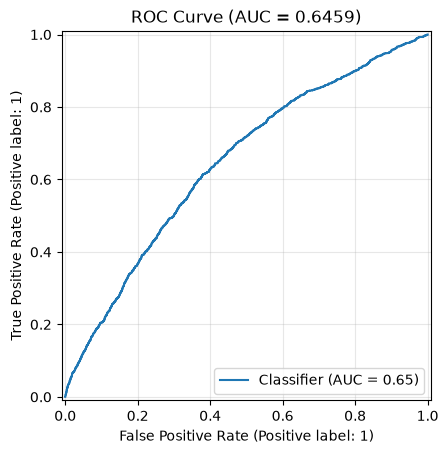

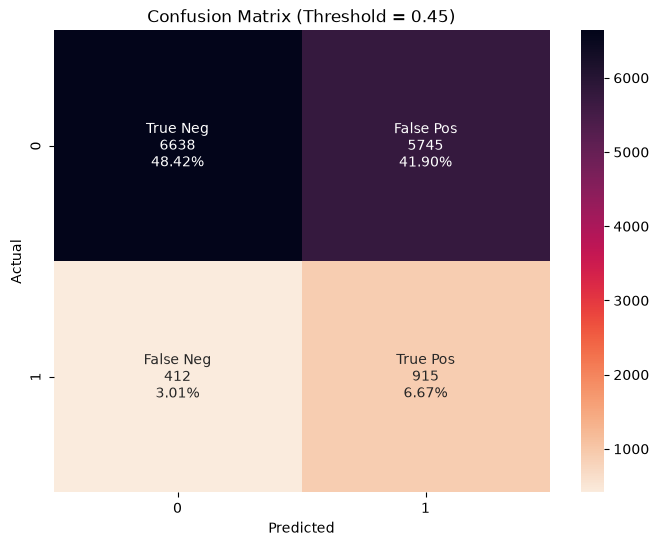


Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.54      0.68     12383
           1       0.14      0.69      0.23      1327

    accuracy                           0.55     13710
   macro avg       0.54      0.61      0.46     13710
weighted avg       0.86      0.55      0.64     13710

ROC-AUC: 0.6458807718314258
PR-AUC: 0.1609948103877012
MCC: 0.13345123529679284
CV mean: [0.64181341 0.61270685 0.62218007 0.62126158 0.63744471 0.61518614
 0.6215612  0.63095501 0.62442145 0.61963037]



In [49]:
for name, X in X_experiments.items():
    feature = list(X_experiments[name].drop(columns="12-Month Default Flag"))
    print("="*50)
    print(f"The title model is: {name}")
    print("="*50)
    x_train, x_val, y_train, y_val = Set_up_data_sendmodel(X_experiments[name],feature)
    print(x_train.shape)
    if "12-Month Default Flag" in feature:
        print("feature training mustn't have target feature")
    print()
    xgb_en_Big, y_prob_en_Big_xgb, cv_scores_en_Big_xgb = train_evaluate_model(
        xgb_clf,
        x_train,
        y_train,
        x_val,
        y_val
    )   
    y_pred_en = model_evaluation(
        xgb_en_Big,
        x_val,
        y_val,
        threshold=0.45,
        y_prob=y_prob_en_Big_xgb
    )
    print(f"CV mean: {cv_scores_en_Big_xgb}")
    print()
        


In [50]:
for name, X in X_experiments.items():
    print(name)

baseline
original
financial
contact
interaction
financial_contact
all_features
financial_frequency


The title model is: baseline
Train: (54836, 25) (54836,)
Validation: (13710, 25) (13710,)

Train Distribution:
0    0.903239
1    0.096761
Name: proportion, dtype: float64

Validation Distribution:
0    0.903209
1    0.096791
Name: proportion, dtype: float64
(54836, 25)

CV ROC-AUC: 0.6454
CV STD: 0.0072

Validation ROC-AUC: 0.6589
Validation PR-AUC: 0.1669


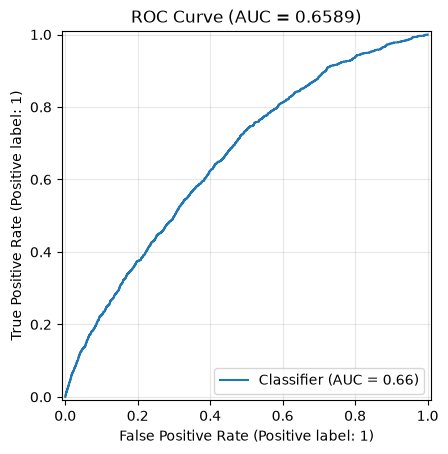

CV mean: [0.65603595 0.63554947 0.65368859 0.63472808 0.64996709 0.64513052
 0.64822984 0.64926749 0.64540269 0.63604993]


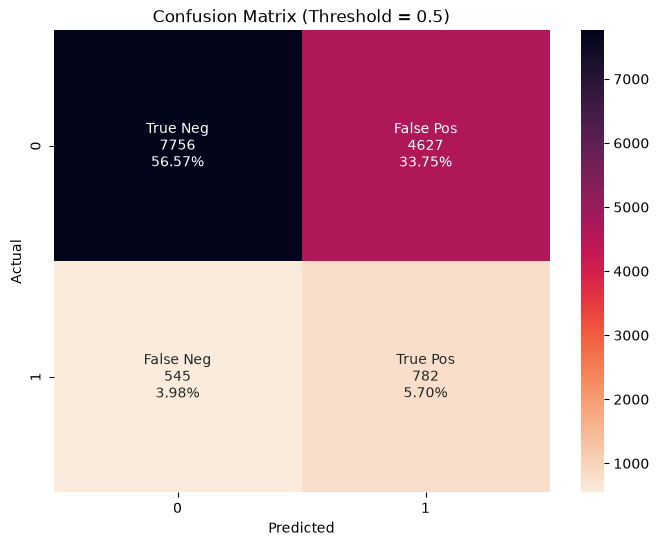


Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.63      0.75     12383
           1       0.14      0.59      0.23      1327

    accuracy                           0.62     13710
   macro avg       0.54      0.61      0.49     13710
weighted avg       0.86      0.62      0.70     13710

ROC-AUC: 0.6588959473026229
PR-AUC: 0.16688263624301597
MCC: 0.130454036826774

The title model is: original
Train: (54836, 38) (54836,)
Validation: (13710, 38) (13710,)

Train Distribution:
0    0.903239
1    0.096761
Name: proportion, dtype: float64

Validation Distribution:
0    0.903209
1    0.096791
Name: proportion, dtype: float64
(54836, 38)

CV ROC-AUC: 0.6451
CV STD: 0.0073

Validation ROC-AUC: 0.6565
Validation PR-AUC: 0.1655


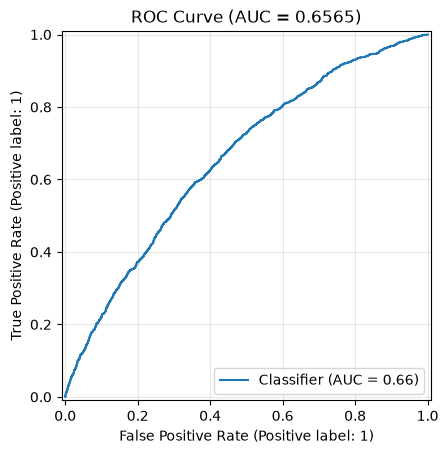

CV mean: [0.65680628 0.63472799 0.65143366 0.63645649 0.65141358 0.64944594
 0.64164837 0.64856313 0.64433412 0.63577963]


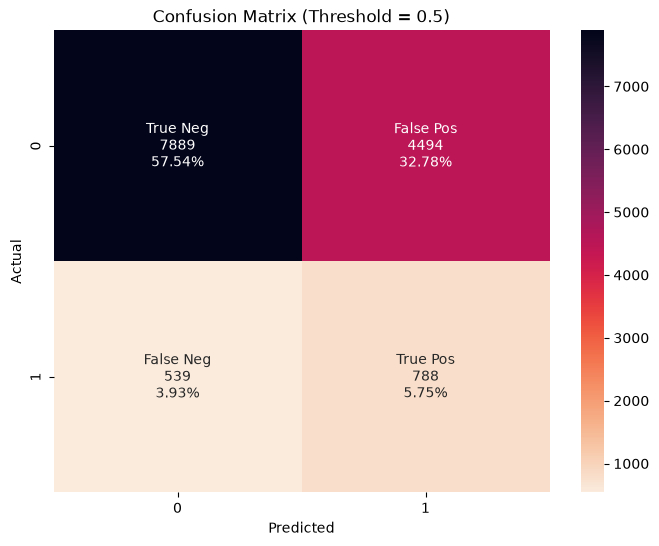


Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.64      0.76     12383
           1       0.15      0.59      0.24      1327

    accuracy                           0.63     13710
   macro avg       0.54      0.62      0.50     13710
weighted avg       0.86      0.63      0.71     13710

ROC-AUC: 0.6565135577064626
PR-AUC: 0.16552152902499864
MCC: 0.14028715709513492

The title model is: financial
Train: (54836, 44) (54836,)
Validation: (13710, 44) (13710,)

Train Distribution:
0    0.903239
1    0.096761
Name: proportion, dtype: float64

Validation Distribution:
0    0.903209
1    0.096791
Name: proportion, dtype: float64
(54836, 44)

CV ROC-AUC: 0.6443
CV STD: 0.0073

Validation ROC-AUC: 0.6591
Validation PR-AUC: 0.1641


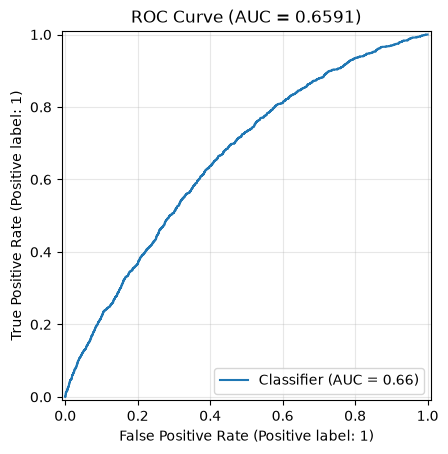

CV mean: [0.65790683 0.63484026 0.65055965 0.63441287 0.64901459 0.6440889
 0.64304138 0.64669001 0.6473643  0.63549629]


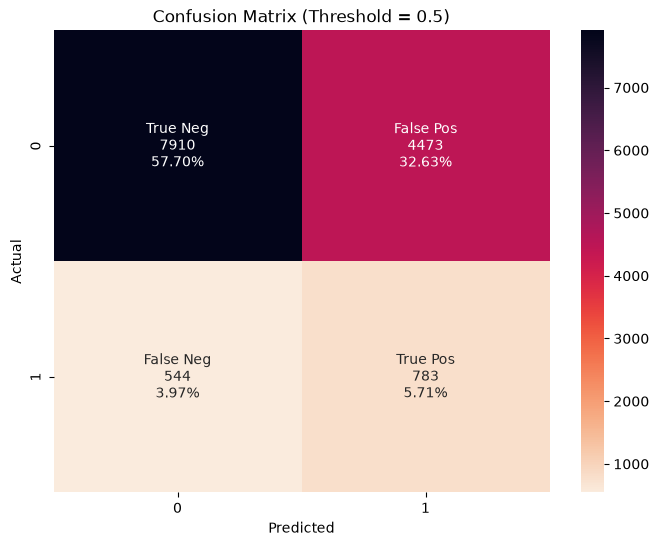


Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.64      0.76     12383
           1       0.15      0.59      0.24      1327

    accuracy                           0.63     13710
   macro avg       0.54      0.61      0.50     13710
weighted avg       0.86      0.63      0.71     13710

ROC-AUC: 0.6590505823277544
PR-AUC: 0.1640614443724417
MCC: 0.13915724628573842

The title model is: contact
Train: (54836, 42) (54836,)
Validation: (13710, 42) (13710,)

Train Distribution:
0    0.903239
1    0.096761
Name: proportion, dtype: float64

Validation Distribution:
0    0.903209
1    0.096791
Name: proportion, dtype: float64
(54836, 42)

CV ROC-AUC: 0.6449
CV STD: 0.0068

Validation ROC-AUC: 0.6570
Validation PR-AUC: 0.1657


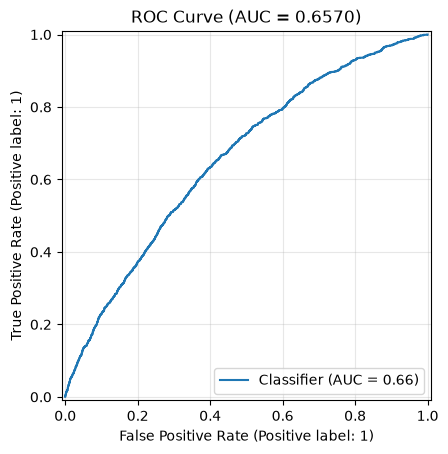

CV mean: [0.65641104 0.63646876 0.65134603 0.63615298 0.65061122 0.64638943
 0.64287298 0.64796685 0.64524047 0.63560085]


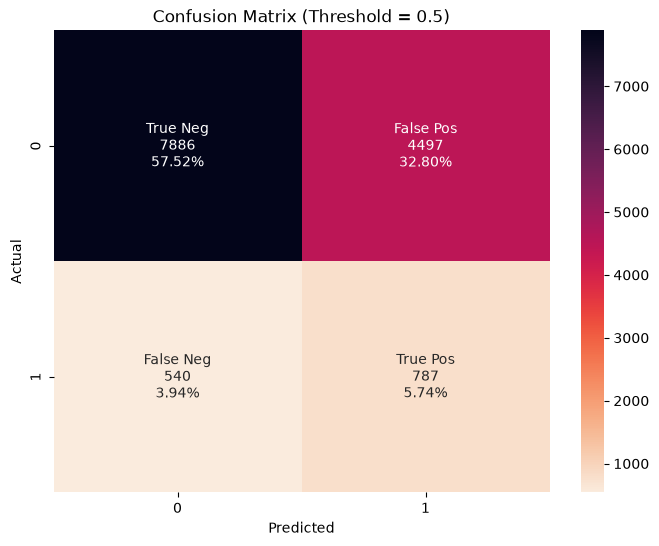


Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.64      0.76     12383
           1       0.15      0.59      0.24      1327

    accuracy                           0.63     13710
   macro avg       0.54      0.61      0.50     13710
weighted avg       0.86      0.63      0.71     13710

ROC-AUC: 0.6569584757185585
PR-AUC: 0.16566481481898687
MCC: 0.13967225930018665

The title model is: interaction
Train: (54836, 41) (54836,)
Validation: (13710, 41) (13710,)

Train Distribution:
0    0.903239
1    0.096761
Name: proportion, dtype: float64

Validation Distribution:
0    0.903209
1    0.096791
Name: proportion, dtype: float64
(54836, 41)

CV ROC-AUC: 0.6328
CV STD: 0.0088

Validation ROC-AUC: 0.6514
Validation PR-AUC: 0.1628


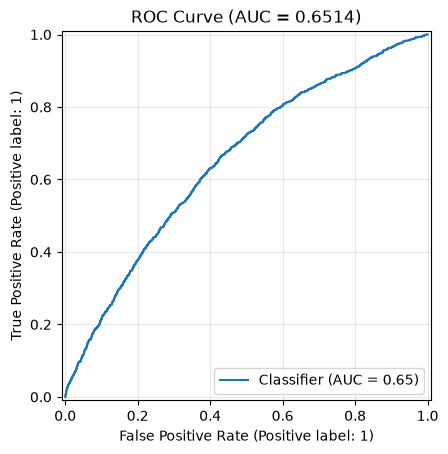

CV mean: [0.64917741 0.61842412 0.63419156 0.62571994 0.64499519 0.62919266
 0.63256192 0.63637438 0.6331698  0.62468609]


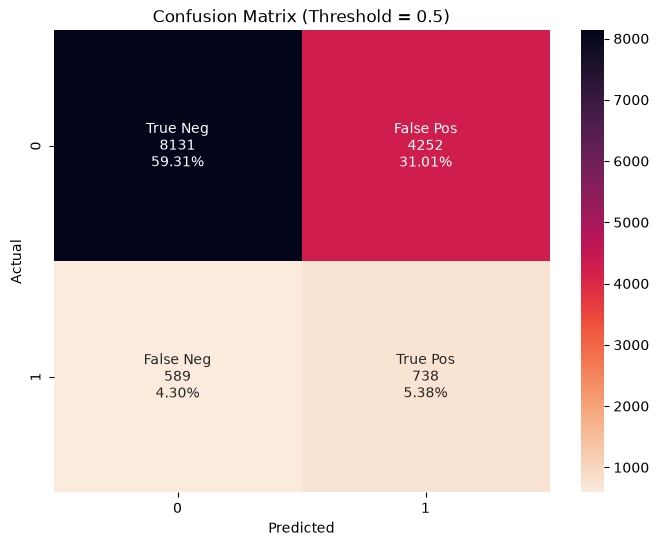


Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.66      0.77     12383
           1       0.15      0.56      0.23      1327

    accuracy                           0.65     13710
   macro avg       0.54      0.61      0.50     13710
weighted avg       0.86      0.65      0.72     13710

ROC-AUC: 0.651399586946175
PR-AUC: 0.16277321367999043
MCC: 0.13075116471801096

The title model is: financial_contact
Train: (54836, 48) (54836,)
Validation: (13710, 48) (13710,)

Train Distribution:
0    0.903239
1    0.096761
Name: proportion, dtype: float64

Validation Distribution:
0    0.903209
1    0.096791
Name: proportion, dtype: float64
(54836, 48)

CV ROC-AUC: 0.6444
CV STD: 0.0075

Validation ROC-AUC: 0.6589
Validation PR-AUC: 0.1648


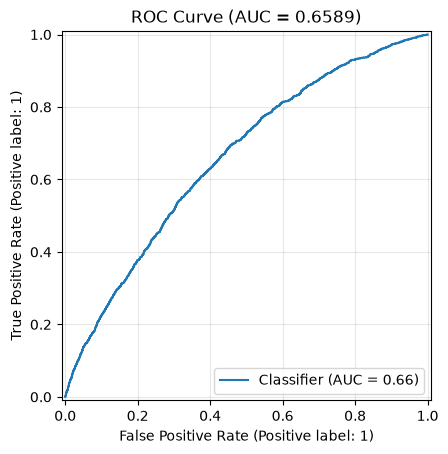

CV mean: [0.65921299 0.63530171 0.64978394 0.63395665 0.64934712 0.64385982
 0.64361102 0.64843725 0.64548652 0.63548116]


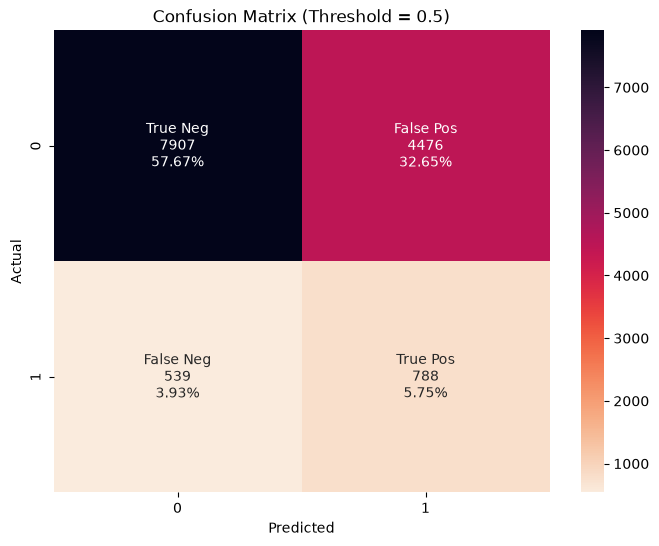


Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.64      0.76     12383
           1       0.15      0.59      0.24      1327

    accuracy                           0.63     13710
   macro avg       0.54      0.62      0.50     13710
weighted avg       0.86      0.63      0.71     13710

ROC-AUC: 0.6588719700496115
PR-AUC: 0.16475671514720058
MCC: 0.14126069441794864

The title model is: all_features
Train: (54836, 65) (54836,)
Validation: (13710, 65) (13710,)

Train Distribution:
0    0.903239
1    0.096761
Name: proportion, dtype: float64

Validation Distribution:
0    0.903209
1    0.096791
Name: proportion, dtype: float64
(54836, 65)

CV ROC-AUC: 0.6326
CV STD: 0.0087

Validation ROC-AUC: 0.6503
Validation PR-AUC: 0.1605


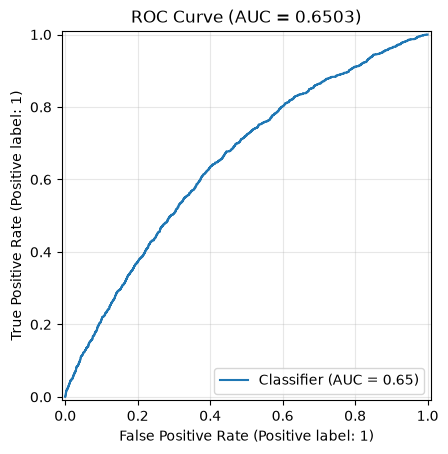

CV mean: [0.64914338 0.61851004 0.63395655 0.62644161 0.64415801 0.62816273
 0.63172198 0.63742821 0.63204975 0.62404053]


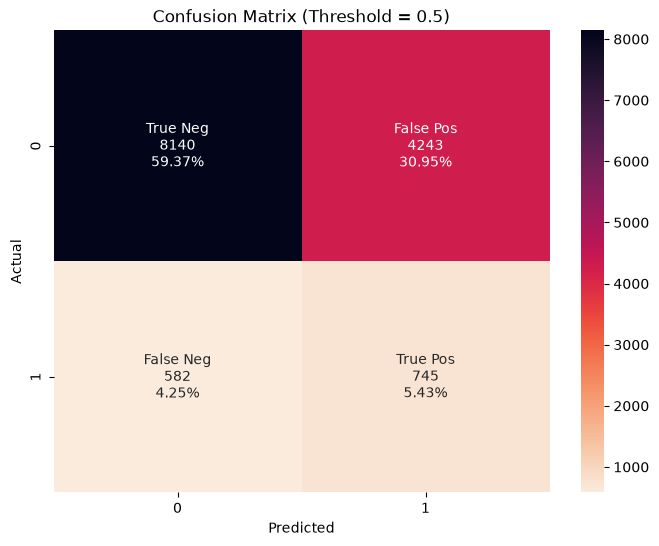


Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.66      0.77     12383
           1       0.15      0.56      0.24      1327

    accuracy                           0.65     13710
   macro avg       0.54      0.61      0.50     13710
weighted avg       0.86      0.65      0.72     13710

ROC-AUC: 0.6503029623287537
PR-AUC: 0.160460840895863
MCC: 0.13445099220925175

The title model is: financial_frequency
Train: (54836, 67) (54836,)
Validation: (13710, 67) (13710,)

Train Distribution:
0    0.903239
1    0.096761
Name: proportion, dtype: float64

Validation Distribution:
0    0.903209
1    0.096791
Name: proportion, dtype: float64
(54836, 67)

CV ROC-AUC: 0.6323
CV STD: 0.0091

Validation ROC-AUC: 0.6495
Validation PR-AUC: 0.1582


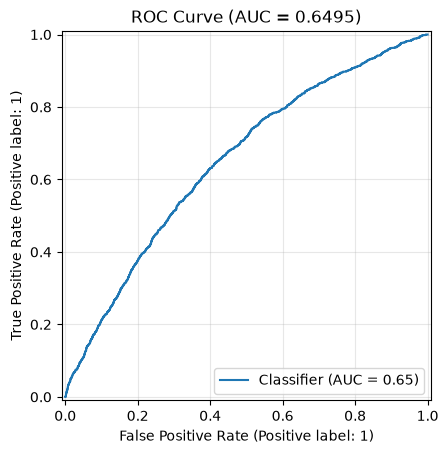

CV mean: [0.6470399  0.61708162 0.63373791 0.62812302 0.64766886 0.62711113
 0.63100706 0.6364974  0.63151142 0.62348479]


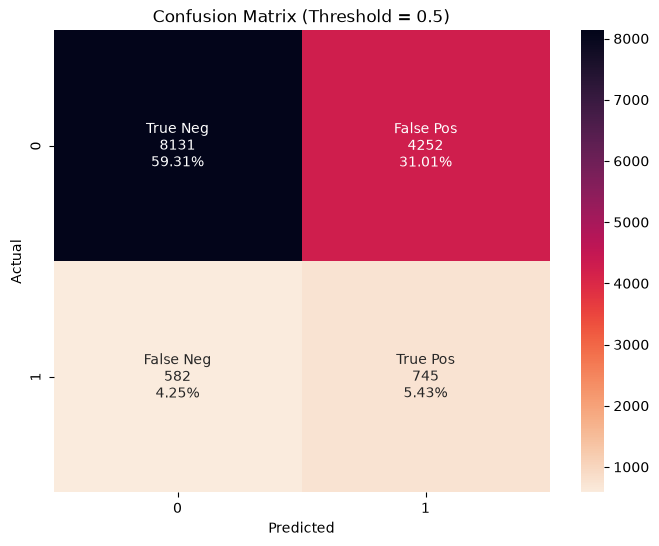


Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.66      0.77     12383
           1       0.15      0.56      0.24      1327

    accuracy                           0.65     13710
   macro avg       0.54      0.61      0.50     13710
weighted avg       0.86      0.65      0.72     13710

ROC-AUC: 0.6494537780939312
PR-AUC: 0.15824442031081357
MCC: 0.1339527133088245



In [51]:
for name, X in X_experiments.items():
    feature = list(X_experiments[name].drop(columns="12-Month Default Flag"))
    print("="*60)
    print(f"The title model is: {name}")
    print("="*60)
    x_train, x_val, y_train, y_val = Set_up_data_sendmodel(X_experiments[name],feature)
    print(x_train.shape)
    if "12-Month Default Flag" in feature:
        print("feature training mustn't have target feature")
    print()
    clf_en_Big, y_prob_en_Big, cv_scores_en_Big = train_evaluate_model(
        lgbm_clf_en,
        x_train,
        y_train,
        x_val,
        y_val
    )   
    print(f"CV mean: {cv_scores_en_Big}")
    y_pred_en = model_evaluation(
        clf_en_Big,
        x_val,
        y_val,
        threshold=0.5,
        y_prob=y_prob_en_Big
    )
    print()
        


##

##

#### ==================
#### LinghtGBM model 
#### ==================

Train: (54836, 44) (54836,)
Validation: (13710, 44) (13710,)

Train Distribution:
0    0.903239
1    0.096761
Name: proportion, dtype: float64

Validation Distribution:
0    0.903209
1    0.096791
Name: proportion, dtype: float64
(54836, 44)

CV ROC-AUC: 0.6443
CV STD: 0.0073

Validation ROC-AUC: 0.6591
Validation PR-AUC: 0.1641


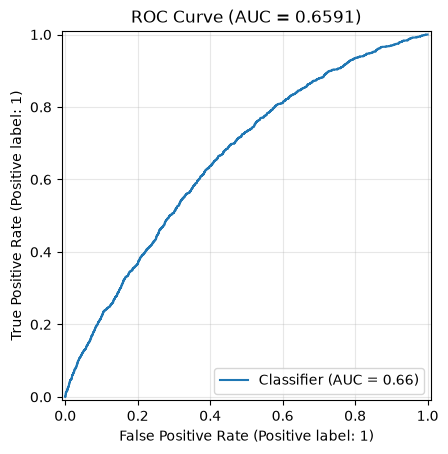

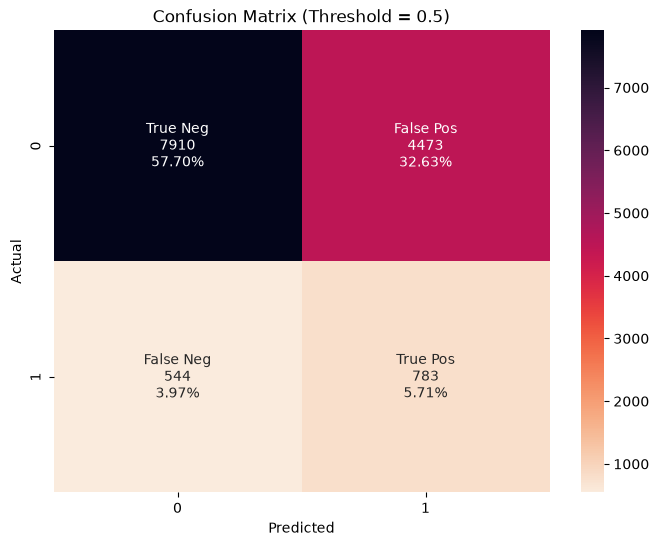


Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.64      0.76     12383
           1       0.15      0.59      0.24      1327

    accuracy                           0.63     13710
   macro avg       0.54      0.61      0.50     13710
weighted avg       0.86      0.63      0.71     13710

ROC-AUC: 0.6590505823277544
PR-AUC: 0.1640614443724417
MCC: 0.13915724628573842


In [78]:
feature = list(X_experiments['financial'].drop(columns="12-Month Default Flag"))
x_train, x_val, y_train, y_val = Set_up_data_sendmodel(X_experiments['financial'],feature)
print(x_train.shape)
if "12-Month Default Flag" in feature:
    print("feature training mustn't have target feature")
print()
clf_en_Big, y_prob_en_Big, cv_scores_en_Big = train_evaluate_model(
    lgbm_clf_en,
    x_train,
    y_train,
    x_val,
    y_val
)   

y_pred_en = model_evaluation(
    clf_en_Big,
    x_val,
    y_val,
    threshold=0.5,
    y_prob=y_prob_en_Big
)

Train: (54836, 48) (54836,)
Validation: (13710, 48) (13710,)

Train Distribution:
0    0.903239
1    0.096761
Name: proportion, dtype: float64

Validation Distribution:
0    0.903209
1    0.096791
Name: proportion, dtype: float64
(54836, 48)

CV ROC-AUC: 0.6444
CV STD: 0.0075

Validation ROC-AUC: 0.6589
Validation PR-AUC: 0.1648


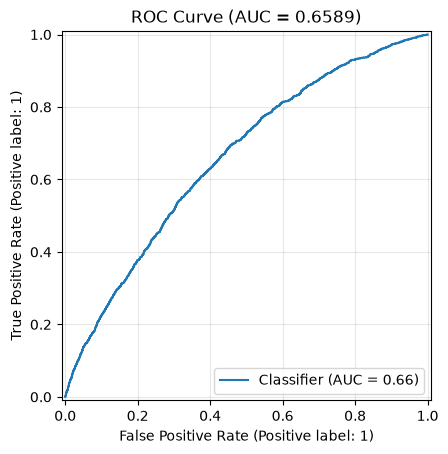

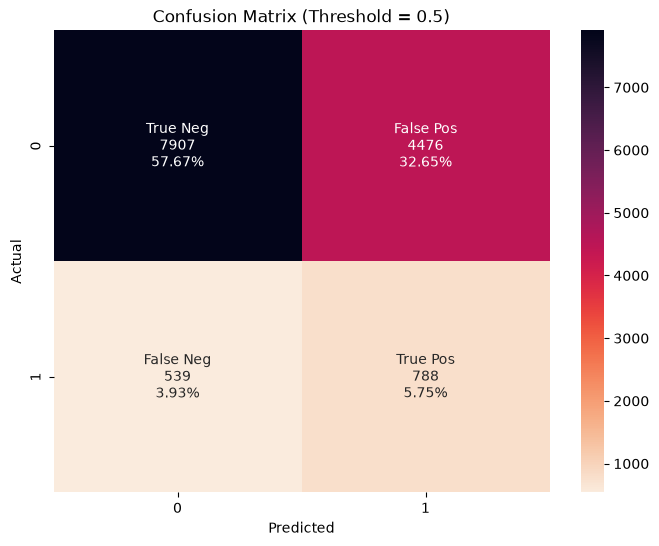


Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.64      0.76     12383
           1       0.15      0.59      0.24      1327

    accuracy                           0.63     13710
   macro avg       0.54      0.62      0.50     13710
weighted avg       0.86      0.63      0.71     13710

ROC-AUC: 0.6588719700496115
PR-AUC: 0.16475671514720058
MCC: 0.14126069441794864


In [85]:
feature = list(X_experiments['financial_contact'].drop(columns="12-Month Default Flag"))
x_train, x_val, y_train, y_val = Set_up_data_sendmodel(X_experiments['financial_contact'],feature)
print(x_train.shape)
if "12-Month Default Flag" in feature:
    print("feature training mustn't have target feature")
print()
clf_en_finance_contact, y_prob_en_finance_freq, cv_scores_en_Big = train_evaluate_model(
    lgbm_clf_en,
    x_train,
    y_train,
    x_val,
    y_val
)   

y_pred_en = model_evaluation(
    clf_en_finance_contact,
    x_val,
    y_val,
    threshold=0.5,
    y_prob=y_prob_en_finance_freq
)

##

##

## Test Set for submission

In [86]:
feature_test_Big_engineer = [
       'Application Channel', 'Gender',
       'Marital Status', 'Age (in months)', 'Residence Period (in months)',
       'Occupation Category', 'Industry Category', 'Employment Type Category',
       'Insurance Type', 'Company Size Category', 'Business Entity Type',
       'Declared Annual Income', 'Payday', 'Declared Number of Borrowings',
       'Declared Borrowing Amount', 'Desired Credit Limit', 'Residence Type',
       'Rent Burden', 'Residence Ownership Status', 'Number of Dependents',
       'Number of Dependent Children', 'Home Phone Number Available',
       'Mobile Phone Number Available', 'Employer Phone Number Available',
       'Driver Licence Number Available'
    
]

In [87]:
test_experiments = {
    name: build_features(
        test_data,
        groups=groups,
        baseline_features=feature_test_Big_engineer
    )
    for name, groups in EXPERIMENTS.items()
}


# Inspect feature counts
for name, X in test_experiments.items():

    print(
        f'{name:25s} | '
        f'Features: {X.shape[1]} | '
        f'Shape: {X.shape}'
    )

baseline                  | Features: 25 | Shape: (137091, 25)
original                  | Features: 38 | Shape: (137091, 38)
financial                 | Features: 44 | Shape: (137091, 44)
contact                   | Features: 42 | Shape: (137091, 42)
interaction               | Features: 41 | Shape: (137091, 41)
financial_contact         | Features: 48 | Shape: (137091, 48)
all_features              | Features: 65 | Shape: (137091, 65)
financial_frequency       | Features: 67 | Shape: (137091, 67)


In [88]:
# 1. Predict
# Predict probability
y_prob = clf_en_finance_contact.predict_proba(test_experiments['financial_contact'])[:, 1]

# Set threshold = 0.30
threshold = 0.50
y_pred = (y_prob >= threshold).astype(int)

# 2. Create submission with ID from test set
submission = pd.DataFrame({
    'ID': test_data['ID'].values,
    '12-Month Default Flag': y_prob
})
submission[["12-Month Default Flag"]].value_counts()

12-Month Default Flag
0.378355                 4
0.239538                 2
0.288696                 2
0.236515                 1
0.448040                 1
                        ..
0.436344                 1
0.295631                 1
0.353798                 1
0.275654                 1
0.444147                 1
Name: count, Length: 137086, dtype: int64

In [89]:
target = '12-Month Default Flag'

# Count
print(submission[target].value_counts())

# Percentage
print(submission[target].value_counts(normalize=True) * 100)

12-Month Default Flag
0.378355    4
0.239538    2
0.288696    2
0.236515    1
0.448040    1
           ..
0.436344    1
0.295631    1
0.353798    1
0.275654    1
0.444147    1
Name: count, Length: 137086, dtype: int64
12-Month Default Flag
0.378355    0.002918
0.239538    0.001459
0.288696    0.001459
0.236515    0.000729
0.448040    0.000729
              ...   
0.436344    0.000729
0.295631    0.000729
0.353798    0.000729
0.275654    0.000729
0.444147    0.000729
Name: proportion, Length: 137086, dtype: float64


In [90]:
# 3. Export CSV
submission.to_csv(
    'submission_first_model.csv',
    float_format='%.2f',
    index=False
)

# 4. Check result
display(submission.head())

print("Shape:", submission.shape)
print("Missing values:\n", submission.isnull().sum())
print(submission[target].value_counts(normalize=True) * 100)

,ID,12-Month Default Flag
0,211850001,0.236515
1,211850002,0.448040
2,211850003,0.279056
3,211870001,0.517429
4,211880001,0.667819


Shape: (137091, 2)
Missing values:
 ID                       0
12-Month Default Flag    0
dtype: int64
12-Month Default Flag
0.378355    0.002918
0.239538    0.001459
0.288696    0.001459
0.236515    0.000729
0.448040    0.000729
              ...   
0.436344    0.000729
0.295631    0.000729
0.353798    0.000729
0.275654    0.000729
0.444147    0.000729
Name: proportion, Length: 137086, dtype: float64
